Perfect. Since you have the images both locally and on Google Drive, we can use whichever environment is more convenient.

I recommend doing the initial audit in Google Colab, because:
- Your dataset is already on Google Drive.
- We can inspect images directly in notebook cells.
- We can generate annotation CSV files.
- We can later train the new model using the same environment.
We will keep your existing dataset untouched. All auditing will happen using a separate working directory.

In [ ]:

import os
import pandas as pd
import random

# Dataset location in Google Drive
DATASET_DIR = "/content/drive/MyDrive/Food_data/split_dataset"

# Output directory for the audit
AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
os.makedirs(AUDIT_DIR, exist_ok=True)

SPLITS = ["train", "validation", "test"]

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

records = []

# Scan all existing dataset splits
for split in SPLITS:
    split_path = os.path.join(DATASET_DIR, split)
    for category in sorted(os.listdir(split_path)):
        category_path = os.path.join(split_path, category)

        if not os.path.isdir(category_path):
            continue

        for filename in os.listdir(category_path):
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                records.append({
                    "image_path": os.path.join(category_path, filename),
                    "filename": filename,
                    "original_category": category,
                    "original_split": split
                })

# Create inventory
inventory = pd.DataFrame(records)

print("Total images found:", len(inventory))
print("\nImages by original category:")
print(inventory["original_category"].value_counts())

# Save complete inventory
inventory.to_csv(
    os.path.join(AUDIT_DIR, "complete_inventory.csv"),
    index=False
)

# Select 10 random images from each category
random.seed(42)

pilot = (
    inventory.groupby("original_category", group_keys=False)
    .apply(lambda group: group.sample(
        n=min(10, len(group)),
        random_state=42
    ))
    .reset_index(drop=True)
)

# Add 13 multi-label columns
FOOD_CLASSES = sorted(inventory["original_category"].unique())

for food in FOOD_CLASSES:
    pilot[food] = ""

# Add review fields
pilot["review_status"] = "pending"
pilot["notes"] = ""

# Save pilot annotation sheet
pilot_path = os.path.join(AUDIT_DIR, "pilot_annotations.csv")

pilot.to_csv(pilot_path, index=False)

print("\nPilot images selected:", len(pilot))
print("Number of food categories:", len(FOOD_CLASSES))
print("\nFiles saved in:", AUDIT_DIR)
print("Pilot annotation file:", pilot_path)


Total images found: 6462

Images by original category:
original_category
chapati        857
nyamachoma     783
bhaji          627
ugali          623
mandazi        618
kachumbari     484
matoke         481
githeri        477
masalachips    435
sukumawiki     398
pilau          298
mukimo         210
kukuchoma      171
Name: count, dtype: int64

Pilot images selected: 130
Number of food categories: 13

Files saved in: /content/drive/MyDrive/Food_data/dataset_audit
Pilot annotation file: /content/drive/MyDrive/Food_data/dataset_audit/pilot_annotations.csv


/tmp/ipykernel_373/560765446.py:54: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


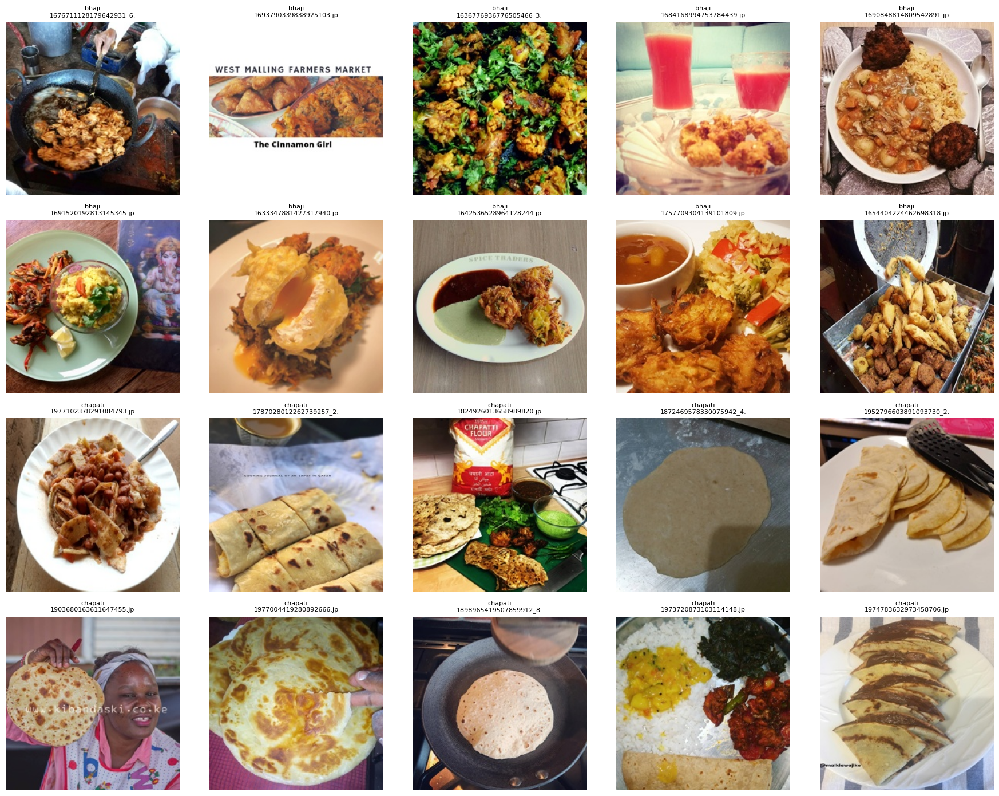

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# Display the first 20 pilot images
sample = pilot.head(20)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f'{row["original_category"]}\n{row["filename"][:22]}',
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


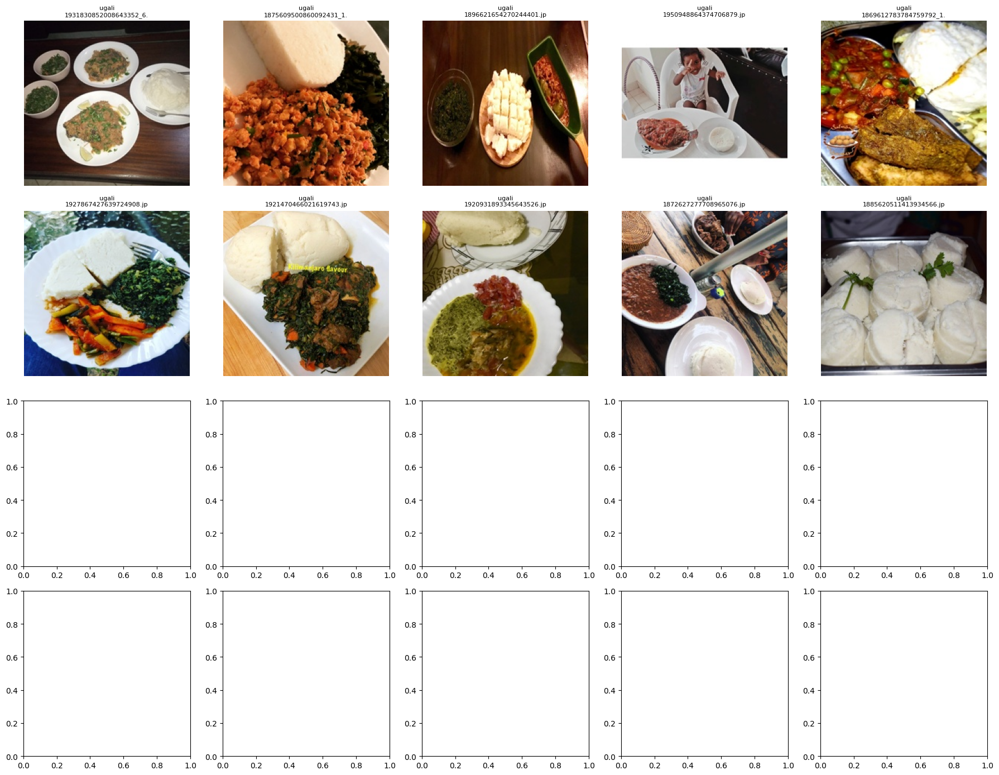

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Display pilot images 21–40
sample = pilot.iloc[120:130]

fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f'{row["original_category"]}\n{row["filename"][:22]}',
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

pilot_path = "/content/drive/MyDrive/Food_data/dataset_audit/pilot_annotations.csv"

pilot = pd.read_csv(pilot_path)

print("Pilot images loaded:", len(pilot))

Pilot images loaded: 130


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

# Load the full inventory and existing pilot
inventory = pd.read_csv(os.path.join(AUDIT_DIR, "complete_inventory.csv"))
pilot = pd.read_csv(os.path.join(AUDIT_DIR, "pilot_annotations.csv"))

# Exclude images already sampled
used_files = set(pilot["filename"])

# Find additional Nyama Choma images
available = inventory[
    (inventory["original_category"] == "nyamachoma") &
    (~inventory["filename"].isin(used_files))
]

# Randomly select 20
extra = available.sample(n=20, random_state=42).copy()

# Add the food-label columns
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "Avocado", "Spaghetti", "Chips", "Tilapia"
]

for food in food_classes:
    extra[food] = ""

extra["reviewed"] = "pending"
extra["notes"] = ""

# Save the extra sample
extra_path = os.path.join(AUDIT_DIR, "extra_nyamachoma_sample.csv")
extra.to_csv(extra_path, index=False)

print("Additional images selected:", len(extra))
print("Saved to:", extra_path)

Additional images selected: 20
Saved to: /content/drive/MyDrive/Food_data/dataset_audit/extra_nyamachoma_sample.csv


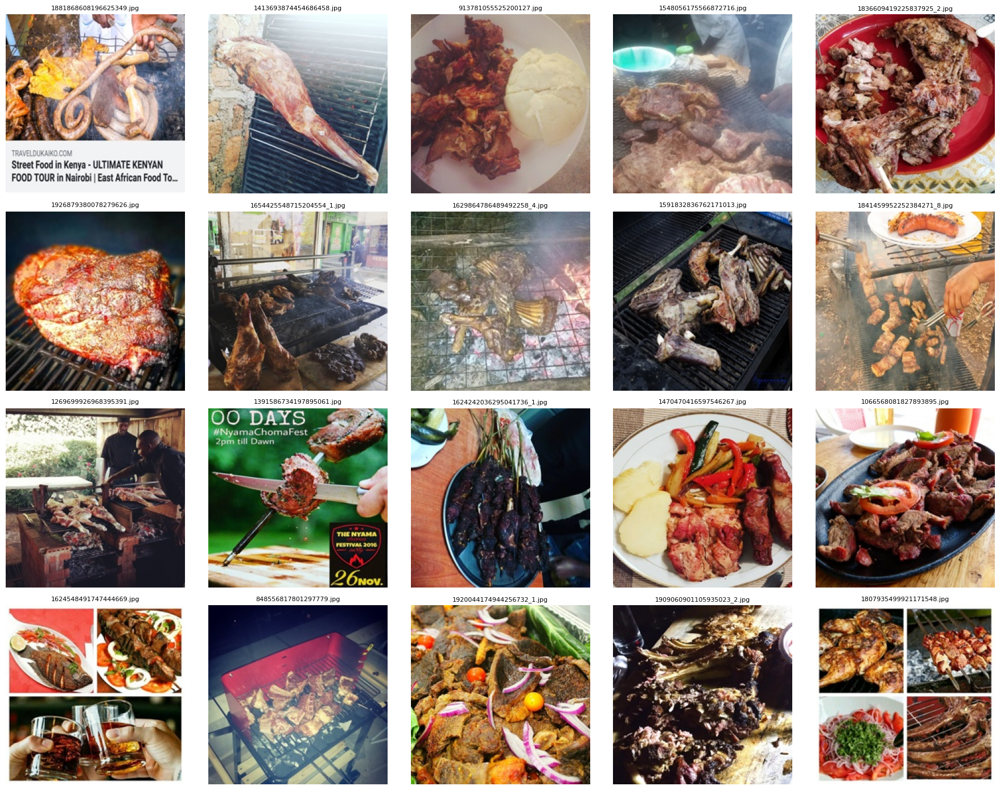

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for ax, (_, row) in zip(axes.flat, extra.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(row["filename"][:25], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import pandas as pd

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

# Add every completed annotation CSV here.
ANNOTATION_FILES = [
    "pilot_annotations.csv",
    "extra_nyamachoma_sample.csv",
    # Add other completed batches below, if you have them.
]

# Food classes in your annotation spreadsheet.
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Standardise label column names.
rename_labels = {
    "Avocado": "avocado",
    "Chips": "chips",
    "Spaghetti": "spaghetti",
    "Tilapia": "tilapia"
}

frames = []

for filename in ANNOTATION_FILES:
    path = os.path.join(AUDIT_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing annotation file: {path}")

    df = pd.read_csv(path)
    df = df.rename(columns=rename_labels)

    required = ["filename", "image_path", "reviewed"] + food_classes
    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"{filename} is missing these columns: {missing}"
        )

    frames.append(df)

# Combine annotation batches.
master = pd.concat(frames, ignore_index=True)

# Explicitly mark the seven unsuitable images.
unsuitable_files = [
    "1691520192813145345.jpg",
    "1633347881427317940.jpg",
    "1608845981212755560_1.jpg",
    "1611214054885836086.jpg",
    "544929070745332305.jpg",
    "1678299297421932789.jpg",
    "1920044174944256732_1.jpg"
]

master.loc[
    master["filename"].isin(unsuitable_files), "reviewed"
] = "unsuitable"

# Remove exact duplicate rows.
master = master.drop_duplicates()

# Check whether any image appears more than once.
duplicates = master[
    master.duplicated(subset=["image_path"], keep=False)
]

if len(duplicates) > 0:
    print("WARNING: Duplicate image paths found:")
    print(duplicates[["filename", "image_path"]].to_string(index=False))
    raise ValueError("Resolve duplicate image entries before continuing.")

# Keep only fully reviewed, suitable images.
usable = master[master["reviewed"].str.lower() == "reviewed"].copy()

# Check that every food label is 0 or 1.
for col in food_classes:
    usable[col] = pd.to_numeric(usable[col], errors="coerce")

    if usable[col].isna().any():
        raise ValueError(
            f"Missing or invalid values found in label column: {col}"
        )

    if not usable[col].isin([0, 1]).all():
        raise ValueError(f"Non-binary values found in: {col}")

# Save the master and cleaned annotation files.
master.to_csv(
    os.path.join(AUDIT_DIR, "master_annotations_all.csv"),
    index=False
)

usable.to_csv(
    os.path.join(AUDIT_DIR, "final_annotations.csv"),
    index=False
)

# Display summary.
print("ANNOTATION SUMMARY")
print("------------------")
print("Total annotation rows:", len(master))
print("Suitable reviewed images:", len(usable))
print("Unsuitable images:", (master["reviewed"].str.lower() == "unsuitable").sum())
print("Pending/unreviewed images:", len(master) - len(usable) -
      (master["reviewed"].str.lower() == "unsuitable").sum())

print("\nFOOD CLASS COUNTS")
print("-----------------")
print(usable[food_classes].sum().sort_values(ascending=False))

print("\nSaved master_annotations_all.csv and final_annotations.csv")


ANNOTATION SUMMARY
------------------
Total annotation rows: 150
Suitable reviewed images: 143
Unsuitable images: 7
Pending/unreviewed images: 0

FOOD CLASS COUNTS
-----------------
kukuchoma      26
kachumbari     22
ugali          22
nyamachoma     21
sukumawiki     19
chapati        13
pilau          13
matoke         12
githeri        12
mandazi        10
mukimo         10
masalachips    10
beef           10
bhaji           8
beef_stew       8
rice            5
samosa          4
tilapia         4
beans           3
avocado         3
chips           2
spaghetti       1
dtype: int64

Saved master_annotations_all.csv and final_annotations.csv


In [ ]:

import os
import pandas as pd

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

inventory = pd.read_csv(
    os.path.join(AUDIT_DIR, "complete_inventory.csv")
)

master = pd.read_csv(
    os.path.join(AUDIT_DIR, "master_annotations_all.csv")
)

# Identify images that have not yet been annotated.
annotated_paths = set(master["image_path"])

remaining = inventory[
    ~inventory["image_path"].isin(annotated_paths)
].copy()

print("REMAINING IMAGES:", len(remaining))
print("\nREMAINING IMAGES BY ORIGINAL CATEGORY:")
print(remaining["original_category"].value_counts().sort_index())

# Save the remaining inventory.
remaining.to_csv(
    os.path.join(AUDIT_DIR, "remaining_images.csv"),
    index=False
)


REMAINING IMAGES: 6312

REMAINING IMAGES BY ORIGINAL CATEGORY:
original_category
bhaji          617
chapati        847
githeri        467
kachumbari     474
kukuchoma      161
mandazi        608
masalachips    425
matoke         471
mukimo         200
nyamachoma     753
pilau          288
sukumawiki     388
ugali          613
Name: count, dtype: int64


In [ ]:

import os
from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps

# Google Drive locations
EXTRAS_DIR = Path("/content/drive/MyDrive/Food_data/Extras")
OUTPUT_DIR = Path("/content/drive/MyDrive/Food_data/Extras_standardised")
AUDIT_DIR = Path("/content/drive/MyDrive/Food_data/dataset_audit")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# All food labels used in the project
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

supported_formats = {".jpg", ".jpeg", ".png", ".webp"}

records = []
failed = []
category_counts = {}

# Find images inside category subfolders
image_files = [
    p for p in EXTRAS_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in supported_formats
]

print("Images found:", len(image_files))

for index, image_path in enumerate(sorted(image_files), start=1):

    relative_path = image_path.relative_to(EXTRAS_DIR)

    # Use the first folder inside Extras as the food category
    if len(relative_path.parts) < 2:
        failed.append((str(image_path), "Image is not inside a food category folder"))
        continue

    category = relative_path.parts[0].strip().lower()

    if category not in food_classes:
        failed.append((str(image_path), f"Unknown category folder: {category}"))
        continue

    try:
        # Open, correct orientation, convert to RGB and resize
        with Image.open(image_path) as img:
            img = ImageOps.exif_transpose(img)
            img = img.convert("RGB")
            img = img.resize((224, 224), Image.Resampling.LANCZOS)

            # Save with a unique filename
            category_counts[category] = category_counts.get(category, 0) + 1
            new_filename = f"{category}_{category_counts[category]:04d}.jpg"

            category_output = OUTPUT_DIR / category
            category_output.mkdir(parents=True, exist_ok=True)

            output_path = category_output / new_filename
            img.save(output_path, "JPEG", quality=95)

        # Prepare annotation CSV row
        record = {
            "image_path": str(output_path),
            "filename": new_filename,
            "source_filename": image_path.name,
            "original_image_path": str(image_path),
            "original_category": category,
            "original_split": "extras",
        }

        for food in food_classes:
            record[food] = ""

        record["reviewed"] = "pending"
        record["notes"] = ""

        records.append(record)

    except Exception as e:
        failed.append((str(image_path), str(e)))

# Save annotation inventory
extras_df = pd.DataFrame(records)

csv_path = AUDIT_DIR / "extras_annotations.csv"
extras_df.to_csv(csv_path, index=False)

# Report
print("\nSTANDARDISATION SUMMARY")
print("-----------------------")
print("Images found:", len(image_files))
print("Successfully standardised:", len(records))
print("Failed or skipped:", len(failed))

print("\nIMAGES BY FOOD CATEGORY")
print("-----------------------")
print(extras_df["original_category"].value_counts().sort_index())

print("\nAnnotation CSV saved to:")
print(csv_path)

if failed:
    print("\nFAILED OR SKIPPED FILES:")
    for path, reason in failed:
        print(path, "->", reason)


Images found: 44

STANDARDISATION SUMMARY
-----------------------
Images found: 44
Successfully standardised: 44
Failed or skipped: 0

IMAGES BY FOOD CATEGORY
-----------------------
original_category
avocado       7
beans        11
chips         4
samosa        8
spaghetti     7
tilapia       7
Name: count, dtype: int64

Annotation CSV saved to:
/content/drive/MyDrive/Food_data/dataset_audit/extras_annotations.csv


In [ ]:

import os
import pandas as pd

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

# Load previous annotations and newly completed Extras annotations
old = pd.read_csv(
    os.path.join(AUDIT_DIR, "master_annotations_all.csv")
)

extras = pd.read_csv(
    os.path.join(AUDIT_DIR, "extras_annotations.csv")
)

# Standardise label names
rename_labels = {
    "Avocado": "avocado",
    "Chips": "chips",
    "Spaghetti": "spaghetti",
    "Tilapia": "tilapia"
}

old = old.rename(columns=rename_labels)
extras = extras.rename(columns=rename_labels)

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

required_columns = [
    "image_path", "filename", "reviewed"
] + food_classes

# Check required columns
for name, df in [("Old annotations", old), ("Extras", extras)]:
    missing = [c for c in required_columns if c not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Combine records
combined = pd.concat(
    [old, extras],
    ignore_index=True,
    sort=False
)

combined["reviewed"] = (
    combined["reviewed"].astype(str).str.strip().str.lower()
)

# Check duplicate image paths
duplicates = combined[
    combined.duplicated(subset=["image_path"], keep=False)
]

if not duplicates.empty:
    print("Duplicate image paths found:")
    print(duplicates[["filename", "image_path"]].to_string(index=False))
    raise ValueError("Resolve duplicate image paths before continuing.")

# Validate labels for reviewed images
reviewed = combined[combined["reviewed"] == "reviewed"].copy()

for col in food_classes:
    reviewed[col] = pd.to_numeric(reviewed[col], errors="coerce")

    if reviewed[col].isna().any():
        raise ValueError(f"Missing labels found in {col}")

    if not reviewed[col].isin([0, 1]).all():
        raise ValueError(f"Invalid labels found in {col}")

# Separate unsuitable and pending images
unsuitable = combined[combined["reviewed"] == "unsuitable"]
pending = combined[combined["reviewed"] != "reviewed"]
usable = reviewed.copy()

# Save updated files
combined.to_csv(
    os.path.join(AUDIT_DIR, "combined_annotations_v2.csv"),
    index=False
)

usable.to_csv(
    os.path.join(AUDIT_DIR, "final_annotations_v2.csv"),
    index=False
)

# Report
print("UPDATED ANNOTATION SUMMARY")
print("--------------------------")
print("Total records:", len(combined))
print("Suitable reviewed images:", len(usable))
print("Unsuitable images:", len(unsuitable))
print("Pending/unreviewed images:", len(pending))

print("\nFOOD CLASS COUNTS")
print("-----------------")
print(usable[food_classes].sum().sort_values(ascending=False))

print("\nFILES SAVED SUCCESSFULLY")
print("combined_annotations_v2.csv")
print("final_annotations_v2.csv")


UPDATED ANNOTATION SUMMARY
--------------------------
Total records: 194
Suitable reviewed images: 187
Unsuitable images: 7
Pending/unreviewed images: 7

FOOD CLASS COUNTS
-----------------
kukuchoma      27
ugali          27
kachumbari     25
sukumawiki     23
nyamachoma     22
chapati        17
githeri        15
beans          14
avocado        14
beef_stew      13
pilau          13
matoke         12
samosa         12
mandazi        11
tilapia        11
rice           11
masalachips    10
mukimo         10
beef           10
bhaji           8
spaghetti       8
chips           7
dtype: int64

FILES SAVED SUCCESSFULLY
combined_annotations_v2.csv
final_annotations_v2.csv


In [ ]:

import pandas as pd
import os

path = "/content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_v2.csv"

df = pd.read_csv(path)

df["reviewed"] = df["reviewed"].astype(str).str.strip().str.lower()

print("CORRECTED REVIEW STATUS")
print("-----------------------")
print("Total images:", len(df))
print("Reviewed:", (df["reviewed"] == "reviewed").sum())
print("Unsuitable:", (df["reviewed"] == "unsuitable").sum())
print("Actually pending:", (df["reviewed"] == "pending").sum())

print("\nPENDING IMAGES")
print("--------------")

print(
    df.loc[
        df["reviewed"] == "pending",
        ["filename", "original_category", "image_path"]
    ].to_string(index=False)
)



CORRECTED REVIEW STATUS
-----------------------
Total images: 194
Reviewed: 187
Unsuitable: 7
Actually pending: 0

PENDING IMAGES
--------------
Empty DataFrame
Columns: [filename, original_category, image_path]
Index: []


In [ ]:

import pandas as pd

path = "/content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_v2.csv"

df = pd.read_csv(path)

df["reviewed"] = df["reviewed"].astype(str).str.strip().str.lower()

print("ALL REVIEW STATUSES")
print(df["reviewed"].value_counts(dropna=False))

# Find records that are neither reviewed nor unsuitable
unclassified = df[
    ~df["reviewed"].isin(["reviewed", "unsuitable"])
]

print("\nUNCLASSIFIED RECORDS")
print("--------------------")

print(
    unclassified[
        ["filename", "original_category", "reviewed"]
    ].to_string(index=False)
)



ALL REVIEW STATUSES
reviewed
reviewed      187
unsuitable      7
Name: count, dtype: int64

UNCLASSIFIED RECORDS
--------------------
Empty DataFrame
Columns: [filename, original_category, reviewed]
Index: []


In [ ]:

import os
import pandas as pd

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

ANNOTATION_FILE = os.path.join(
    AUDIT_DIR, "final_annotations_v2.csv"
)

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Load manually verified annotations
df = pd.read_csv(ANNOTATION_FILE)

print("Initial images:", len(df))

# Check required columns
required_columns = ["image_path", "filename", "reviewed"] + food_classes

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Keep only manually reviewed suitable images
df["reviewed"] = df["reviewed"].astype(str).str.strip().str.lower()

df = df[df["reviewed"] == "reviewed"].copy()

# Check that image files exist
df["file_exists"] = df["image_path"].apply(os.path.isfile)

missing_files = df[~df["file_exists"]]

print("Missing image files:", len(missing_files))

if len(missing_files) > 0:
    print(missing_files[["filename", "image_path"]])
    raise ValueError("Some image files are missing.")

df = df.drop(columns=["file_exists"])

# Check duplicate image paths
duplicates = df[df.duplicated("image_path", keep=False)]

if len(duplicates) > 0:
    print(duplicates[["filename", "image_path"]])
    raise ValueError("Duplicate images detected.")

# Validate all food labels
for col in food_classes:
    df[col] = pd.to_numeric(df[col], errors="coerce")

    if df[col].isna().any():
        raise ValueError(f"Missing labels in {col}")

    if not df[col].isin([0, 1]).all():
        raise ValueError(f"Invalid labels in {col}")

# Ensure each image has at least one food label
empty_labels = df[food_classes].sum(axis=1) == 0

if empty_labels.any():
    print("Images with no positive labels:")
    print(df.loc[empty_labels, "filename"].tolist())
    raise ValueError("Some images have no food labels.")

# Save clean model-ready annotations
output_path = os.path.join(
    AUDIT_DIR, "model_ready_annotations.csv"
)

df.to_csv(output_path, index=False)

print("\nDATASET PREPARATION SUMMARY")
print("---------------------------")
print("Suitable images:", len(df))
print("Food classes:", len(food_classes))
print("Missing files:", len(missing_files))
print("Duplicate images:", len(duplicates))

print("\nPOSITIVE EXAMPLES PER FOOD")
print("--------------------------")
print(df[food_classes].sum().sort_values(ascending=False))

print("\nSaved to:", output_path)


Initial images: 187
Missing image files: 0

DATASET PREPARATION SUMMARY
---------------------------
Suitable images: 187
Food classes: 22
Missing files: 0
Duplicate images: 0

POSITIVE EXAMPLES PER FOOD
--------------------------
kukuchoma      27
ugali          27
kachumbari     25
sukumawiki     23
nyamachoma     22
chapati        17
githeri        15
beans          14
avocado        14
beef_stew      13
pilau          13
matoke         12
samosa         12
mandazi        11
tilapia        11
rice           11
masalachips    10
mukimo         10
beef           10
bhaji           8
spaghetti       8
chips           7
dtype: int64

Saved to: /content/drive/MyDrive/Food_data/dataset_audit/model_ready_annotations.csv


In [ ]:

!pip -q install iterative-stratification

import os
import numpy as np
import pandas as pd

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

# Load manually verified annotations
df = pd.read_csv(
    os.path.join(AUDIT_DIR, "model_ready_annotations.csv")
).reset_index(drop=True)

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Features are dummy identifiers; labels drive the stratification.
X = np.arange(len(df)).reshape(-1, 1)
y = df[food_classes].values.astype(int)

# First split: 85% train/validation, 15% test
split_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(split_1.split(X, y))

# Second split: 70% train, 15% validation overall
# 15% of the original dataset is 17.647% of the remaining 85%.
split_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_rel, val_rel = next(
    split_2.split(X[trainval_idx], y[trainval_idx])
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

# Create the three datasets
train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()

# Save split files
SPLIT_DIR = os.path.join(AUDIT_DIR, "model_splits")
os.makedirs(SPLIT_DIR, exist_ok=True)

train_df.to_csv(os.path.join(SPLIT_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(SPLIT_DIR, "validation.csv"), index=False)
test_df.to_csv(os.path.join(SPLIT_DIR, "test.csv"), index=False)

# Display dataset sizes
print("DATASET SPLIT SUMMARY")
print("---------------------")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

# Display positive examples for each class
counts = pd.DataFrame({
    "Training": train_df[food_classes].sum(),
    "Validation": val_df[food_classes].sum(),
    "Testing": test_df[food_classes].sum(),
    "Total": df[food_classes].sum()
})

print("\nFOOD LABEL DISTRIBUTION")
print("-----------------------")
print(counts.to_string())

# Identify classes missing from any split
print("\nCLASSES WITH ZERO POSITIVE EXAMPLES IN A SPLIT")
print("----------------------------------------------")

for split_name in ["Training", "Validation", "Testing"]:
    missing = counts.index[counts[split_name] == 0].tolist()
    print(f"{split_name}: {missing if missing else 'None'}")

# Verify no image appears in multiple splits
assert set(train_df.image_path).isdisjoint(val_df.image_path)
assert set(train_df.image_path).isdisjoint(test_df.image_path)
assert set(val_df.image_path).isdisjoint(test_df.image_path)

print("\nNo image overlap between splits.")
print("Split files saved in:", SPLIT_DIR)


DATASET SPLIT SUMMARY
---------------------
Training images: 128
Validation images: 27
Testing images: 32
Total images: 187

FOOD LABEL DISTRIBUTION
-----------------------
             Training  Validation  Testing  Total
bhaji               6           1        1      8
chapati            11           3        3     17
githeri            11           2        2     15
kachumbari         16           4        5     25
kukuchoma          19           4        4     27
mandazi             7           2        2     11
masalachips         7           1        2     10
matoke              8           2        2     12
mukimo              7           1        2     10
nyamachoma         16           3        3     22
pilau               9           2        2     13
sukumawiki         16           3        4     23
ugali              19           4        4     27
samosa              8           2        2     12
rice                7           2        2     11
beef                7      

In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

# Paths
BASE_DIR = "/content/drive/MyDrive/Food_data"
SPLIT_DIR = os.path.join(BASE_DIR, "dataset_audit", "model_splits")

train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test.csv"))

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
NUM_CLASSES = len(food_classes)

# Convert image paths and labels into TensorFlow datasets
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe[food_classes].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            len(dataframe), seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TENSORFLOW VERSION:", tf.__version__)
print("GPU AVAILABLE:", tf.config.list_physical_devices("GPU"))

print("\nDATASET PREPARATION")
print("-------------------")
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))
print("Image size:", IMAGE_SIZE)
print("Output classes:", NUM_CLASSES)

# Check one batch
images, labels = next(iter(train_ds))

print("\nIMAGE BATCH SHAPE:", images.shape)
print("LABEL BATCH SHAPE:", labels.shape)


TENSORFLOW VERSION: 2.21.0
GPU AVAILABLE: []

DATASET PREPARATION
-------------------
Training batches: 16
Validation batches: 4
Testing batches: 4
Image size: (224, 224)
Output classes: 22

IMAGE BATCH SHAPE: (8, 224, 224, 3)
LABEL BATCH SHAPE: (8, 22)


In [ ]:

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build multi-label classification model
inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)

# MobileNetV2 preprocessing
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

# Extract image features
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │        28,182 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,286,166 (8.72 MB)

 Trainable params: 28,182 (110.09 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

MODEL_PATH = os.path.join(
    BASE_DIR, "multilabel_mobilenetv2_best.keras"
)

callbacks = [
    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

# Save training history
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(BASE_DIR, "mobilenetv2_training_history.csv"),
    index=False
)

print("\nTraining completed.")
print("Best model saved at:", MODEL_PATH)


Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - binary_accuracy: 0.5804 - loss: 0.7452 - precision: 0.0899 - recall: 0.4868
Epoch 1: val_loss improved from None to 0.56712, saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 26s 990ms/step - binary_accuracy: 0.6119 - loss: 0.6956 - precision: 0.0855 - recall: 0.4091 - val_binary_accuracy: 0.7239 - val_loss: 0.5671 - val_precision: 0.0857 - val_recall: 0.2500 - learning_rate: 1.0000e-04
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - binary_accuracy: 0.7325 - loss: 0.5556 - precision: 0.0928 - recall: 0.2733
Epoch 2: val_loss improved from 0.56712 to 0.44942, saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras
16/16 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    f1_score,
    hamming_loss,
    precision_score,
    recall_score
)

# Load the best saved model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras"
)

# Get actual labels and model predictions
y_true = test_df[food_classes].values.astype(int)
y_prob = model.predict(test_ds)

# Convert probabilities into predictions using 0.5 threshold
y_pred = (y_prob >= 0.5).astype(int)

print("TEST SET EVALUATION")
print("-------------------")

print("Micro Precision:", round(precision_score(y_true, y_pred, average="micro", zero_division=0), 4))
print("Micro Recall:", round(recall_score(y_true, y_pred, average="micro", zero_division=0), 4))
print("Micro F1 Score:", round(f1_score(y_true, y_pred, average="micro", zero_division=0), 4))

print("Macro F1 Score:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Hamming Loss:", round(hamming_loss(y_true, y_pred), 4))

print("\nAVERAGE LABELS PER IMAGE")
print("Actual:", round(y_true.sum(axis=1).mean(), 2))
print("Predicted:", round(y_pred.sum(axis=1).mean(), 2))

print("\nPER-CLASS PERFORMANCE")
print(classification_report(
    y_true,
    y_pred,
    target_names=food_classes,
    zero_division=0
))


4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 515ms/step
TEST SET EVALUATION
-------------------
Micro Precision: 0.3333
Micro Recall: 0.0192
Micro F1 Score: 0.0364
Macro F1 Score: 0.0182
Hamming Loss: 0.0753

AVERAGE LABELS PER IMAGE
Actual: 1.62
Predicted: 0.09

PER-CLASS PERFORMANCE
              precision    recall  f1-score   support

       bhaji       0.00      0.00      0.00         1
     chapati       0.00      0.00      0.00         3
     githeri       0.00      0.00      0.00         2
  kachumbari       0.00      0.00      0.00         5
   kukuchoma       0.00      0.00      0.00         4
     mandazi       0.00      0.00      0.00         2
 masalachips       0.00      0.00      0.00         2
      matoke       0.00      0.00      0.00         2
      mukimo       0.00      0.00      0.00         2
  nyamachoma       0.00      0.00      0.00         3
       pilau       0.00      0.00      0.00         2
  sukumawiki       0.00      0.00      0.00         4
       ugali       1.00     

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf

# Load the best saved model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Food_data/multilabel_mobilenetv2_best.keras"
)

# Get predictions from the validation dataset
val_probabilities = model.predict(val_ds)

# Inspect the probability distribution
print("PROBABILITY ANALYSIS")
print("--------------------")
print("Minimum:", np.min(val_probabilities))
print("Maximum:", np.max(val_probabilities))
print("Mean:", np.mean(val_probabilities))

print("\nPREDICTIONS AT DIFFERENT THRESHOLDS")

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    predictions = (val_probabilities >= threshold).astype(int)

    print(
        f"Threshold {threshold}: "
        f"{predictions.sum()} total predicted labels, "
        f"{predictions.sum(axis=1).mean():.2f} labels per image"
    )

# Display the strongest predictions
print("\nTOP 10 PREDICTION SCORES")
print(np.sort(val_probabilities.flatten())[-10:])



4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
PROBABILITY ANALYSIS
--------------------
Minimum: 0.00087598455
Maximum: 0.723117
Mean: 0.08471991

PREDICTIONS AT DIFFERENT THRESHOLDS
Threshold 0.1: 170 total predicted labels, 6.30 labels per image
Threshold 0.2: 45 total predicted labels, 1.67 labels per image
Threshold 0.3: 16 total predicted labels, 0.59 labels per image
Threshold 0.4: 4 total predicted labels, 0.15 labels per image
Threshold 0.5: 1 total predicted labels, 0.04 labels per image

TOP 10 PREDICTION SCORES
[0.3777229  0.37807935 0.38422704 0.39261892 0.3973857  0.39833352
 0.40743768 0.4374601  0.44732463 0.723117  ]


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

# Actual validation labels
y_val = val_df[food_classes].values.astype(int)

# Test different thresholds
results = []

for threshold in np.arange(0.05, 0.51, 0.05):
    predictions = (val_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, average="micro", zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, average="micro", zero_division=0
        ),
        "Micro F1": f1_score(
            y_val, predictions, average="micro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Labels per image": predictions.sum(axis=1).mean()
    })

results_df = pd.DataFrame(results)

print("VALIDATION THRESHOLD COMPARISON")
print(results_df.round(3).to_string(index=False))

best_row = results_df.loc[results_df["Micro F1"].idxmax()]

print("\nBEST THRESHOLD BASED ON MICRO F1:")
print(best_row)


VALIDATION THRESHOLD COMPARISON
 Threshold  Precision  Recall  Micro F1  Macro F1  Labels per image
      0.05      0.101   0.708     0.176     0.159            12.519
      0.10      0.141   0.500     0.220     0.197             6.296
      0.15      0.165   0.312     0.216     0.128             3.370
      0.20      0.200   0.188     0.194     0.088             1.667
      0.25      0.160   0.083     0.110     0.062             0.926
      0.30      0.125   0.042     0.062     0.028             0.593
      0.35      0.167   0.042     0.067     0.033             0.444
      0.40      0.250   0.021     0.038     0.018             0.148
      0.45      1.000   0.021     0.041     0.023             0.037
      0.50      1.000   0.021     0.041     0.023             0.037

BEST THRESHOLD BASED ON MICRO F1:
Threshold           0.100000
Precision           0.141176
Recall              0.500000
Micro F1            0.220183
Macro F1            0.197229
Labels per image    6.296296
Name: 1, dt

In [ ]:

import pandas as pd
import os

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

files = [
    "complete_inventory.csv",
    "combined_annotations_v2.csv",
    "final_annotations_v2.csv"
]

for filename in files:
    path = os.path.join(AUDIT_DIR, filename)

    df = pd.read_csv(path)

    print("\nFILE:", filename)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))



FILE: complete_inventory.csv
Rows: 6462
Columns: ['image_path', 'filename', 'original_category', 'original_split']
                                                                        image_path                filename original_category original_split
/content/drive/MyDrive/Food_data/split_dataset/train/bhaji/1541488061782086817.jpg 1541488061782086817.jpg             bhaji          train
/content/drive/MyDrive/Food_data/split_dataset/train/bhaji/1569091368339513063.jpg 1569091368339513063.jpg             bhaji          train

FILE: combined_annotations_v2.csv
Rows: 194
Columns: ['image_path', 'filename', 'original_category', 'original_split', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'notes', 'source_filename', 'original_image_path']
                                       

In [ ]:

import os
import random
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

# --------------------------------------------------
# 1. File locations
# --------------------------------------------------
AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

BATCH_ID = "batch_001_friend"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

# Stop rather than accidentally overwrite an existing batch
if os.path.exists(BATCH_DIR):
    raise FileExistsError(
        f"{BATCH_DIR} already exists. Rename it or check its contents first."
    )

os.makedirs(IMAGES_DIR, exist_ok=True)

# --------------------------------------------------
# 2. Load inventory and previous annotations
# --------------------------------------------------
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)

# Normalise paths before comparing them
def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

already_annotated = set(
    annotated["image_path"].dropna().map(normalise_path)
)

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(already_annotated)
].copy()

# Exclude images assigned in earlier batches
if os.path.exists(ASSIGNMENT_LOG):
    previous_assignments = pd.read_csv(ASSIGNMENT_LOG)
    already_assigned = set(
        previous_assignments["image_path"].dropna().map(normalise_path)
    )
    available = available[
        ~available["image_path"].map(normalise_path).isin(already_assigned)
    ].copy()

print("Available images:", len(available))

# --------------------------------------------------
# 3. Select 50 images across the 13 categories
# --------------------------------------------------
random.seed(42)

categories = sorted(available["original_category"].unique())
random.shuffle(categories)

# Select 4 images from 11 categories and 3 from 2 categories
categories_with_four = set(categories[:11])

selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough available images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=42)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, selected {len(batch)}")

# --------------------------------------------------
# 4. Define the 22 food labels
# --------------------------------------------------
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# --------------------------------------------------
# 5. Copy and number the images from 2 to 51
# --------------------------------------------------
batch_rows = []

for index, row in batch.iterrows():
    image_id = index + 2
    original_path = row["image_path"]

    if not os.path.exists(original_path):
        raise FileNotFoundError(original_path)

    extension = os.path.splitext(original_path)[1] or ".jpg"
    new_filename = f"{image_id}{extension}"
    destination = os.path.join(IMAGES_DIR, new_filename)

    shutil.copy2(original_path, destination)

    batch_rows.append({
        "image_id": image_id,
        "image_filename": new_filename,
        "image_path": original_path,
        "original_category": row["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "",
        "notes": ""
    })

annotation_template = pd.DataFrame(batch_rows)

CSV_FILE = os.path.join(BATCH_DIR, "annotation_template.csv")
annotation_template.to_csv(CSV_FILE, index=False)

# --------------------------------------------------
# 6. Create a contact sheet showing all 50 images
# --------------------------------------------------
thumbnail_width = 180
thumbnail_height = 150
columns = 5
rows = 10

sheet = Image.new(
    "RGB",
    (columns * thumbnail_width, rows * (thumbnail_height + 25)),
    "white"
)

draw = ImageDraw.Draw(sheet)

for index, row in annotation_template.iterrows():
    image_path = os.path.join(IMAGES_DIR, row["image_filename"])

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumbnail_width - 10, thumbnail_height - 10))

    x = (index % columns) * thumbnail_width
    y = (index // columns) * (thumbnail_height + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text((x + 5, y + thumbnail_height),
              f"Image {row['image_id']}", fill="black")

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# --------------------------------------------------
# 7. Create annotation instructions
# --------------------------------------------------
README = os.path.join(BATCH_DIR, "INSTRUCTIONS.txt")

with open(README, "w") as file:
    file.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 001

Images are numbered 2 to 51.

For each image:
- Open the image using its image number.
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels, not just the folder the image came from.
- Do not guess. If an image cannot be assessed, mark it unsuitable.
- Set reviewed to 'reviewed' when completed.
- Set reviewed to 'unsuitable' if the image cannot be reliably labelled.
- Add any useful explanation in the notes column.

IMPORTANT:
The original_category is only the folder the image came from.
It is not necessarily the complete list of foods in the image.

Save the completed annotation_template.csv and send it back.
""")

# --------------------------------------------------
# 8. Record assignments to prevent duplicates
# --------------------------------------------------
assignment_rows = batch[[
    "image_path", "filename", "original_category", "original_split"
]].copy()

assignment_rows.insert(0, "batch_id", BATCH_ID)
assignment_rows.insert(1, "annotator", "friend")
assignment_rows.insert(2, "image_id", range(2, 52))

if os.path.exists(ASSIGNMENT_LOG):
    old_log = pd.read_csv(ASSIGNMENT_LOG)
    assignment_log = pd.concat(
        [old_log, assignment_rows], ignore_index=True
    )
else:
    assignment_log = assignment_rows

assignment_log.to_csv(ASSIGNMENT_LOG, index=False)

# --------------------------------------------------
# 9. Package everything into one ZIP file
# --------------------------------------------------
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, BATCH_DIR)
            zip_file.write(full_path, relative_path)

# --------------------------------------------------
# 10. Confirm the batch
# --------------------------------------------------
print("\nBATCH CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 2 to 51")
print("\nImages per original category:")
print(batch["original_category"].value_counts().sort_index())

print("\nCSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP FILE:", ZIP_FILE)
print("\nShare the ZIP file with your friend through Google Drive.")


Available images: 6312

BATCH CREATED SUCCESSFULLY
Images: 50
Image numbers: 2 to 51

Images per original category:
original_category
bhaji          4
chapati        3
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          3
sukumawiki     4
ugali          4
Name: count, dtype: int64

CSV: /content/drive/MyDrive/Food_data/annotation_batches/batch_001_friend/annotation_template.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_001_friend/contact_sheet.jpg
ZIP FILE: /content/drive/MyDrive/Food_data/annotation_batches/batch_001_friend.zip

Share the ZIP file with your friend through Google Drive.


In [ ]:

import os
import random
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

BATCH_ID = "batch_002_second_annotator"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("First batch assignment log was not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Second batch already exists. Check its contents.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude previously annotated and assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Images available:", len(available))

# Select 50 images across the 13 categories
random.seed(43)
categories = sorted(available["original_category"].unique())
random.shuffle(categories)

categories_with_four = set(categories[:11])
selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=43)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=43
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# Food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and create annotation template
rows = []

for index, record in batch.iterrows():
    image_id = index + 52
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "",
        "notes": ""
    })

template = pd.DataFrame(rows)
CSV_FILE = os.path.join(BATCH_DIR, "annotation_template.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 002

Images are numbered 52 to 101.

For every image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder tells you every food present.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template.csv and return it.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "second_annotator")
new_assignments.insert(2, "image_id", range(52, 102))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)
updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

print("\nSECOND BATCH CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 52–101")
print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())
print("\nCSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP:", ZIP_FILE)


Images available: 6262

SECOND BATCH CREATED SUCCESSFULLY
Images: 50
Image numbers: 52–101

Category distribution:
original_category
bhaji          3
chapati        4
githeri        4
kachumbari     4
kukuchoma      3
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     4
ugali          4
Name: count, dtype: int64

CSV: /content/drive/MyDrive/Food_data/annotation_batches/batch_002_second_annotator/annotation_template.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_002_second_annotator/contact_sheet.jpg
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_002_second_annotator.zip


In [ ]:

import os
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

BATCH_ID = "batch_003_my_batch"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("Assignment log not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Your batch already exists. Check its contents.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load dataset records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude annotated and previously assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Available images:", len(available))

# Select 50 images across the original categories
categories = sorted(available["original_category"].unique())
categories_with_four = set(categories[:11])

selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=44)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=44
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# Define all 22 food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and prepare annotation CSV
annotation_rows = []

for index, record in batch.iterrows():
    image_id = index + 102
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    annotation_rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "me",
        "notes": ""
    })

template = pd.DataFrame(annotation_rows)

CSV_FILE = os.path.join(BATCH_DIR, "annotation_template.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Create instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 003

Images are numbered 102 to 151.

For every image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder tells you every food present.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template.csv.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "me")
new_assignments.insert(2, "image_id", range(102, 152))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)
updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

# Confirm results
print("\nYOUR BATCH CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 102–151")
print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())
print("\nCSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP:", ZIP_FILE)


Available images: 6212

YOUR BATCH CREATED SUCCESSFULLY
Images: 50
Image numbers: 102–151

Category distribution:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

CSV: /content/drive/MyDrive/Food_data/annotation_batches/batch_003_my_batch/annotation_template.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_003_my_batch/contact_sheet.jpg
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_003_my_batch.zip


In [ ]:

import os
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

BATCH_ID = "batch_004"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("Assignment log not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Batch 4 already exists. Check before proceeding.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load existing records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude previously annotated and assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Available images:", len(available))

# Select 50 images across the 13 original categories
categories = sorted(available["original_category"].unique())

if len(categories) != 13:
    raise ValueError(f"Expected 13 categories, found {len(categories)}")

categories_with_four = set(categories[:11])
selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=45)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=45
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# All 22 food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and create annotation template
annotation_rows = []

for index, record in batch.iterrows():
    image_id = index + 152
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    annotation_rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "",
        "notes": ""
    })

template = pd.DataFrame(annotation_rows)

CSV_FILE = os.path.join(AUDIT_DIR, "annotation_template4.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Create instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 004

Images are numbered 152 to 201.

For each image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder identifies every food.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template4.csv.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "annotator_4")
new_assignments.insert(2, "image_id", range(152, 202))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)

updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP containing images, contact sheet and instructions
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

print("\nBATCH 4 CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 152–201")

print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())

print("\nAnnotation CSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP file:", ZIP_FILE)


Available images: 6162

BATCH 4 CREATED SUCCESSFULLY
Images: 50
Image numbers: 152–201

Category distribution:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

Annotation CSV: /content/drive/MyDrive/Food_data/dataset_audit/annotation_template4.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_004/contact_sheet.jpg
ZIP file: /content/drive/MyDrive/Food_data/annotation_batches/batch_004.zip


In [ ]:

import os
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

BATCH_ID = "batch_005"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("Assignment log not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Batch 5 already exists. Check before proceeding.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load existing records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude all previously annotated and assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Available images:", len(available))

# Select 50 images across the 13 original categories
categories = sorted(available["original_category"].unique())

if len(categories) != 13:
    raise ValueError(f"Expected 13 categories, found {len(categories)}")

categories_with_four = set(categories[:11])
selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=46)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=46
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# All 22 food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and prepare annotation CSV
annotation_rows = []

for index, record in batch.iterrows():
    image_id = index + 202
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    annotation_rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "",
        "notes": ""
    })

template = pd.DataFrame(annotation_rows)

CSV_FILE = os.path.join(AUDIT_DIR, "annotation_template5.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Create instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 005

Images are numbered 202 to 251.

For each image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder identifies every food.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template5.csv.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "annotator_5")
new_assignments.insert(2, "image_id", range(202, 252))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)

updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

print("\nBATCH 5 CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 202–251")

print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())

print("\nAnnotation CSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP file:", ZIP_FILE)


Available images: 6112

BATCH 5 CREATED SUCCESSFULLY
Images: 50
Image numbers: 202–251

Category distribution:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

Annotation CSV: /content/drive/MyDrive/Food_data/dataset_audit/annotation_template5.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_005/contact_sheet.jpg
ZIP file: /content/drive/MyDrive/Food_data/annotation_batches/batch_005.zip


In [ ]:

import os
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

BATCH_ID = "batch_006"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("Assignment log not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Batch 6 already exists. Check before proceeding.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load existing records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude previously annotated and assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Available images:", len(available))

# Select 50 images across the 13 original categories
categories = sorted(available["original_category"].unique())

if len(categories) != 13:
    raise ValueError(f"Expected 13 categories, found {len(categories)}")

categories_with_four = set(categories[:11])
selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=47)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=47
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# Define all 22 food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and create annotation template
annotation_rows = []

for index, record in batch.iterrows():
    image_id = index + 252
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    annotation_rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "me",
        "notes": ""
    })

template = pd.DataFrame(annotation_rows)

# Save annotation CSV directly in dataset_audit
CSV_FILE = os.path.join(AUDIT_DIR, "annotation_template6.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Create instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 006

Images are numbered 252 to 301.

For every image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder identifies every food.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template6.csv.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "me")
new_assignments.insert(2, "image_id", range(252, 302))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)

updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

# Confirm results
print("\nBATCH 6 CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 252–301")

print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())

print("\nAnnotation CSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP file:", ZIP_FILE)


Available images: 6062

BATCH 6 CREATED SUCCESSFULLY
Images: 50
Image numbers: 252–301

Category distribution:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

Annotation CSV: /content/drive/MyDrive/Food_data/dataset_audit/annotation_template6.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_006/contact_sheet.jpg
ZIP file: /content/drive/MyDrive/Food_data/annotation_batches/batch_006.zip


In [ ]:

import os
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"
DATASET_DIR = "/content/drive/MyDrive/Food_data"
BATCH_ROOT = os.path.join(DATASET_DIR, "annotation_batches")

BATCH_ID = "batch_007"
BATCH_DIR = os.path.join(BATCH_ROOT, BATCH_ID)
IMAGES_DIR = os.path.join(BATCH_DIR, "images")

INVENTORY_FILE = os.path.join(AUDIT_DIR, "complete_inventory.csv")
ANNOTATED_FILE = os.path.join(AUDIT_DIR, "combined_annotations_v2.csv")
ASSIGNMENT_LOG = os.path.join(BATCH_ROOT, "assignment_log.csv")

if not os.path.exists(ASSIGNMENT_LOG):
    raise FileNotFoundError("Assignment log not found.")

if os.path.exists(BATCH_DIR):
    raise FileExistsError("Batch 7 already exists. Check before proceeding.")

os.makedirs(IMAGES_DIR, exist_ok=True)

# Load existing records
inventory = pd.read_csv(INVENTORY_FILE)
annotated = pd.read_csv(ANNOTATED_FILE)
assignment_log = pd.read_csv(ASSIGNMENT_LOG)

def normalise_path(path):
    return os.path.normcase(os.path.normpath(str(path)))

# Exclude all previously annotated and assigned images
excluded = set(annotated["image_path"].dropna().map(normalise_path))
excluded.update(assignment_log["image_path"].dropna().map(normalise_path))

available = inventory[
    ~inventory["image_path"].map(normalise_path).isin(excluded)
].copy()

print("Available images:", len(available))

# Select 50 images across the 13 original categories
categories = sorted(available["original_category"].unique())

if len(categories) != 13:
    raise ValueError(f"Expected 13 categories, found {len(categories)}")

categories_with_four = set(categories[:11])
selected_parts = []

for category in categories:
    category_images = available[
        available["original_category"] == category
    ]

    number_to_select = 4 if category in categories_with_four else 3

    if len(category_images) < number_to_select:
        raise ValueError(f"Not enough images in {category}")

    selected_parts.append(
        category_images.sample(n=number_to_select, random_state=48)
    )

batch = pd.concat(selected_parts).sample(
    frac=1, random_state=48
).reset_index(drop=True)

if len(batch) != 50:
    raise ValueError(f"Expected 50 images, got {len(batch)}")

# Define all 22 food labels
food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Copy images and create annotation template
annotation_rows = []

for index, record in batch.iterrows():
    image_id = index + 302
    source = record["image_path"]

    if not os.path.exists(source):
        raise FileNotFoundError(source)

    extension = os.path.splitext(source)[1] or ".jpg"
    filename = f"{image_id}{extension}"

    shutil.copy2(source, os.path.join(IMAGES_DIR, filename))

    annotation_rows.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source,
        "original_category": record["original_category"],
        **{label: "" for label in food_classes},
        "reviewed": "pending",
        "annotator": "me",
        "notes": ""
    })

template = pd.DataFrame(annotation_rows)

# Save annotation CSV in dataset_audit
CSV_FILE = os.path.join(AUDIT_DIR, "annotation_template7.csv")
template.to_csv(CSV_FILE, index=False)

# Create contact sheet
thumb_w, thumb_h = 180, 150
columns, rows_count = 5, 10

sheet = Image.new(
    "RGB",
    (columns * thumb_w, rows_count * (thumb_h + 25)),
    "white"
)
draw = ImageDraw.Draw(sheet)

for index, record in template.iterrows():
    path = os.path.join(IMAGES_DIR, record["image_filename"])

    with Image.open(path) as img:
        img = img.convert("RGB")
        img.thumbnail((thumb_w - 10, thumb_h - 10))

    x = (index % columns) * thumb_w
    y = (index // columns) * (thumb_h + 25)

    sheet.paste(img, (x + 5, y + 5))
    draw.text(
        (x + 5, y + thumb_h),
        f"Image {record['image_id']}",
        fill="black"
    )

CONTACT_SHEET = os.path.join(BATCH_DIR, "contact_sheet.jpg")
sheet.save(CONTACT_SHEET, quality=90)

# Create instructions
with open(os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"), "w") as f:
    f.write("""
KENYAN FOOD IMAGE ANNOTATION - BATCH 007

Images are numbered 302 to 351.

For every image:
- Enter 1 if a food is visible.
- Enter 0 if a food is not visible.
- Consider all 22 food labels.
- Do not assume the original folder identifies every food.
- Mark reviewed as 'reviewed' when completed.
- Mark reviewed as 'unsuitable' if the image cannot be labelled reliably.
- Add explanations in notes where necessary.

Save the completed annotation_template7.csv.
""")

# Update assignment log
new_assignments = batch[
    ["image_path", "filename", "original_category", "original_split"]
].copy()

new_assignments.insert(0, "batch_id", BATCH_ID)
new_assignments.insert(1, "annotator", "me")
new_assignments.insert(2, "image_id", range(302, 352))

updated_log = pd.concat(
    [assignment_log, new_assignments],
    ignore_index=True
)

updated_log.to_csv(ASSIGNMENT_LOG, index=False)

# Create ZIP
ZIP_FILE = os.path.join(BATCH_ROOT, BATCH_ID + ".zip")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, os.path.relpath(path, BATCH_DIR))

# Confirm results
print("\nBATCH 7 CREATED SUCCESSFULLY")
print("Images:", len(os.listdir(IMAGES_DIR)))
print("Image numbers: 302–351")

print("\nCategory distribution:")
print(batch["original_category"].value_counts().sort_index())

print("\nAnnotation CSV:", CSV_FILE)
print("Contact sheet:", CONTACT_SHEET)
print("ZIP file:", ZIP_FILE)


Available images: 6012

BATCH 7 CREATED SUCCESSFULLY
Images: 50
Image numbers: 302–351

Category distribution:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

Annotation CSV: /content/drive/MyDrive/Food_data/dataset_audit/annotation_template7.csv
Contact sheet: /content/drive/MyDrive/Food_data/annotation_batches/batch_007/contact_sheet.jpg
ZIP file: /content/drive/MyDrive/Food_data/annotation_batches/batch_007.zip


In [ ]:
import os
import pandas as pd
import glob

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

files = sorted(glob.glob(
    os.path.join(AUDIT_DIR, "annotation_template*.csv")
))

print("Annotation files found:", len(files))

for file in files:
    df = pd.read_csv(file)
    print(f"{os.path.basename(file)}: {len(df)} images")


Annotation files found: 6
annotation_template1.csv: 50 images
annotation_template2.csv: 50 images
annotation_template3.csv: 50 images
annotation_template4.csv: 50 images
annotation_template6.csv: 50 images
annotation_template7.csv: 50 images


In [ ]:
import os
import glob
import pandas as pd

AUDIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit"

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

files = sorted(glob.glob(
    os.path.join(AUDIT_DIR, "annotation_template*.csv")
))

all_annotations = []

for file in files:
    df = pd.read_csv(file)
    df["batch_file"] = os.path.basename(file)
    all_annotations.append(df)

combined = pd.concat(all_annotations, ignore_index=True)

print("Total images:", len(combined))

print("\nMissing columns:")
print([c for c in food_classes if c not in combined.columns])

print("\nMissing annotation values:")
print(combined[food_classes].isna().sum().sum())

print("\nInvalid label values:")
invalid = {}
for c in food_classes:
    if c in combined.columns:
        values = set(combined[c].dropna().unique())
        if not values.issubset({0, 1}):
            invalid[c] = values

print(invalid)

print("\nReview statuses:")
print(combined["reviewed"].value_counts(dropna=False))

print("\nDuplicate image paths:")
print(combined["image_path"].duplicated().sum())

Total images: 300

Missing columns:
[]

Missing annotation values:
0

Invalid label values:
{}

Review statuses:
reviewed
reviewed       246
unsuitable      52
Unsuitable       1
unsuitable       1
Name: count, dtype: int64

Duplicate image paths:
0


In [ ]:
# Standardise review statuses
combined["reviewed"] = (
    combined["reviewed"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Standardised review statuses:")
print(combined["reviewed"].value_counts())

# Check reviewed images with no food labels
reviewed = combined[combined["reviewed"] == "reviewed"]

all_zero = (reviewed[food_classes].sum(axis=1) == 0)

print("\nReviewed images with no positive labels:", all_zero.sum())

# Check image files exist
missing_images = sum(
    not os.path.exists(path)
    for path in combined["image_path"]
)

print("Missing image files:", missing_images)


Standardised review statuses:
reviewed
reviewed      246
unsuitable     54
Name: count, dtype: int64

Reviewed images with no positive labels: 0
Missing image files: 0


In [ ]:
import pandas as pd
import os

original_file = os.path.join(
    AUDIT_DIR, "model_ready_annotations.csv"
)

original = pd.read_csv(original_file)

print("Original annotations:", len(original))
print("\nOriginal columns:")
print(original.columns.tolist())

print("\nNew batch columns:")
print(combined.columns.tolist())

# Compare required food-label columns
print("\nMissing food labels in original:")
print([c for c in food_classes if c not in original.columns])

print("\nMissing food labels in new batches:")
print([c for c in food_classes if c not in combined.columns])

# Check overlap between original and new image paths
overlap = set(original["image_path"]) & set(combined["image_path"])

print("\nImages appearing in both datasets:", len(overlap))


Original annotations: 187

Original columns:
['image_path', 'filename', 'original_category', 'original_split', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'notes', 'source_filename', 'original_image_path']

New batch columns:
['image_id', 'image_filename', 'image_path', 'original_category', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'annotator', 'notes', 'batch_file']

Missing food labels in original:
[]

Missing food labels in new batches:
[]

Images appearing in both datasets: 0


In [ ]:
import os
from collections import Counter

def get_split(path):
    parts = os.path.normpath(path).lower().split(os.sep)

    for split in ["train", "validation", "test"]:
        if split in parts:
            return split

    return "unknown"

combined["original_split"] = combined["image_path"].apply(get_split)

print("New batch split distribution:")
print(combined["original_split"].value_counts())

print("\nExample image paths:")
for path in combined["image_path"].head(5):
    print(path)

print("\nUnknown split images:")
print(
    combined.loc[
        combined["original_split"] == "unknown",
        ["image_filename", "image_path"]
    ].head(10)
)

New batch split distribution:
original_split
train         199
test           60
validation     41
Name: count, dtype: int64

Example image paths:
/content/drive/MyDrive/Food_data/split_dataset/test/nyamachoma/1152311947812180055.jpg
/content/drive/MyDrive/Food_data/split_dataset/train/kukuchoma/1709422828128231428.jpg
/content/drive/MyDrive/Food_data/split_dataset/train/mukimo/1427704107519293835.jpg
/content/drive/MyDrive/Food_data/split_dataset/train/chapati/1937097734255777659.jpg
/content/drive/MyDrive/Food_data/split_dataset/train/ugali/1863984552290882077.jpg

Unknown split images:
Empty DataFrame
Columns: [image_filename, image_path]
Index: []


In [ ]:
import os
import pandas as pd

# Keep only suitable new annotations
new_data = combined[
    combined["reviewed"] == "reviewed"
].copy()

# Match the original dataset's column names
new_data["filename"] = new_data["image_filename"]
new_data["source_filename"] = new_data["image_filename"]
new_data["original_image_path"] = None

# Keep the required columns
required_columns = [
    "image_path",
    "filename",
    "original_category",
    "original_split"
] + food_classes + [
    "reviewed",
    "notes",
    "source_filename",
    "original_image_path"
]

new_data = new_data[required_columns]

# Combine original and new annotations
final_dataset = pd.concat(
    [original[required_columns], new_data],
    ignore_index=True
)

# Check for duplicate image paths
print("Total annotations:", len(final_dataset))
print("Duplicate paths:", final_dataset["image_path"].duplicated().sum())

print("\nReview statuses:")
print(final_dataset["reviewed"].value_counts())

print("\nSplit distribution:")
print(final_dataset["original_split"].value_counts())

# Save the combined dataset
OUTPUT_FILE = os.path.join(
    AUDIT_DIR,
    "model_ready_annotations_v3.csv"
)

final_dataset.to_csv(OUTPUT_FILE, index=False)

print("\nSaved to:", OUTPUT_FILE)


Total annotations: 433
Duplicate paths: 0

Review statuses:
reviewed
reviewed    433
Name: count, dtype: int64

Split distribution:
original_split
train         256
test           78
validation     55
extras         44
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/Food_data/dataset_audit/model_ready_annotations_v3.csv


In [ ]:
import os
import pandas as pd

SPLIT_DIR = os.path.join(AUDIT_DIR, "model_splits")

for split in ["train", "validation", "test"]:
    file_path = os.path.join(SPLIT_DIR, f"{split}.csv")

    df = pd.read_csv(file_path)

    print(f"\n{split.upper()}: {len(df)} images")

    if "original_split" in df.columns:
        print(df["original_split"].value_counts())

# Inspect the 44 Extras images
extras = final_dataset[
    final_dataset["original_split"] == "extras"
]

print("\nExtras images:", len(extras))
print(extras[["filename", "image_path"]].head(10))


TRAIN: 128 images
original_split
train         62
extras        28
test          20
validation    18
Name: count, dtype: int64

VALIDATION: 27 images
original_split
train         16
extras         8
test           2
validation     1
Name: count, dtype: int64

TEST: 32 images
original_split
train         12
test           8
extras         8
validation     4
Name: count, dtype: int64

Extras images: 44
             filename                                         image_path
143  avocado_0001.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
144  avocado_0002.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
145  avocado_0003.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
146  avocado_0004.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
147  avocado_0005.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
148  avocado_0006.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
149  avocado_0007.jpg  /content/drive/MyDrive/Food_data/Extras_standa...
150    bean

In [ ]:
import numpy as np
import pandas as pd
import os

# Work on a copy
final_dataset = final_dataset.copy()

# Identify Extras
extras_mask = final_dataset["original_split"] == "extras"
extras_indices = final_dataset.index[extras_mask].to_numpy()

# Reproducible random allocation
rng = np.random.default_rng(42)
rng.shuffle(extras_indices)

n = len(extras_indices)
train_end = int(n * 0.70)
val_end = train_end + int(n * 0.15)

final_dataset.loc[extras_indices[:train_end], "original_split"] = "train"
final_dataset.loc[extras_indices[train_end:val_end], "original_split"] = "validation"
final_dataset.loc[extras_indices[val_end:], "original_split"] = "test"

# Save updated annotations
OUTPUT_FILE = os.path.join(
    AUDIT_DIR,
    "model_ready_annotations_v3.csv"
)

final_dataset.to_csv(OUTPUT_FILE, index=False)

print("Final split distribution:")
print(final_dataset["original_split"].value_counts())

print("\nRemaining Extras:",
      (final_dataset["original_split"] == "extras").sum())

print("\nTotal annotations:", len(final_dataset))

Final split distribution:
original_split
train         286
test           86
validation     61
Name: count, dtype: int64

Remaining Extras: 0

Total annotations: 433


In [ ]:
# Check whether any image paths appear in multiple splits

train_paths = set(
    final_dataset.loc[
        final_dataset["original_split"] == "train", "image_path"
    ]
)

val_paths = set(
    final_dataset.loc[
        final_dataset["original_split"] == "validation", "image_path"
    ]
)

test_paths = set(
    final_dataset.loc[
        final_dataset["original_split"] == "test", "image_path"
    ]
)

print("Train-validation overlap:", len(train_paths & val_paths))
print("Train-test overlap:", len(train_paths & test_paths))
print("Validation-test overlap:", len(val_paths & test_paths))

# Check class distribution
print("\nPositive examples per food class:")
print(final_dataset.groupby("original_split")[food_classes].sum().T)


Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Positive examples per food class:
original_split  test  train  validation
bhaji              4     16           3
chapati            5     31          11
githeri            6     29           4
kachumbari        15     33           9
kukuchoma         11     35           7
mandazi            8     24           3
masalachips        5     17           4
matoke            10     14           7
mukimo             8     19           6
nyamachoma        10     35           5
pilau              6     29           4
sukumawiki        14     39           7
ugali              9     41           5
samosa             1     11           1
rice               6      9           6
beef               4     21           5
beef_stew          3     18           5
beans              3      9           4
avocado            7     14           5
spaghetti          2     10           1
chips              0     10           4
tilapia 

In [ ]:
import os
import pandas as pd

SPLIT_OUTPUT = os.path.join(AUDIT_DIR, "model_splits_v3")
os.makedirs(SPLIT_OUTPUT, exist_ok=True)

for split in ["train", "validation", "test"]:

    df = final_dataset[
        final_dataset["original_split"] == split
    ].copy()

    # Save only the required information
    columns = ["image_path"] + food_classes
    df = df[columns]

    output_file = os.path.join(
        SPLIT_OUTPUT, f"{split}.csv"
    )

    df.to_csv(output_file, index=False)

    print(f"{split}: {len(df)} images saved")

# Verify that every image exists
missing = []

for path in final_dataset["image_path"]:
    if not os.path.exists(path):
        missing.append(path)

print("\nMissing image files:", len(missing))
print("Output folder:", SPLIT_OUTPUT)

train: 286 images saved
validation: 61 images saved
test: 86 images saved

Missing image files: 0
Output folder: /content/drive/MyDrive/Food_data/dataset_audit/model_splits_v3


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Paths
SPLIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit/model_splits_v3"

# Settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
NUM_CLASSES = 22
SEED = 42

# Load CSV files
train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test.csv"))

# Function to load and preprocess images
def load_image(path, labels):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)

    return image, labels

# Create TensorFlow datasets
def create_dataset(df, shuffle=False):
    paths = df["image_path"].values
    labels = df[food_classes].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            len(df), seed=SEED, reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# Verify
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Number of food classes:", len(food_classes))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Food_data/dataset_audit/model_splits_v3/train.csv'

In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build the model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),

    # 22 independent food predictions
    layers.Dense(22, activation="sigmoid")
])

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,574 (9.89 MB)

 Trainable params: 333,590 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("GPUs detected:", gpus)

if gpus:
    print("GPU is available!")
else:
    print("GPU is NOT available. Training will use CPU.")

TensorFlow version: 2.21.0
GPUs detected: []
GPU is NOT available. Training will use CPU.


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Paths
SPLIT_DIR = "/content/drive/MyDrive/Food_data/dataset_audit/model_splits_v3"

# Settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

food_classes = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Load CSV files
train_df = pd.read_csv(os.path.join(SPLIT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(SPLIT_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(SPLIT_DIR, "test.csv"))

# Image preprocessing
def load_image(path, labels):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, labels

# Dataset creation
def create_dataset(df, shuffle=False):
    paths = df["image_path"].values
    labels = df[food_classes].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(
            len(df), seed=SEED, reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 36
Validation batches: 8
Testing batches: 11


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(22, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,574 (9.89 MB)

 Trainable params: 333,590 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)

Epoch 1/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - binary_accuracy: 0.6816 - loss: 0.6052 - precision: 0.0806 - recall: 0.3133
Epoch 1: val_loss improved from None to 0.33068, saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - binary_accuracy: 0.7783 - loss: 0.4909 - precision: 0.0795 - recall: 0.1832 - val_binary_accuracy: 0.9173 - val_loss: 0.3307 - val_precision: 0.1667 - val_recall: 0.0093 - learning_rate: 1.0000e-04
Epoch 2/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - binary_accuracy: 0.8882 - loss: 0.3512 - precision: 0.1384 - recall: 0.0650
Epoch 2: val_loss improved from 0.33068 to 0.29128, saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras
36/36 ━━━━━━━━━━━━━━━

In [ ]:
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    hamming_loss
)
import numpy as np

# Load the best saved model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Food_data/multilabel_mobilenetv2_v2_best.keras"
)

# Get predictions
y_true = np.vstack([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds)

# Apply standard 0.5 threshold
y_pred = (y_prob >= 0.5).astype(int)

print("Micro Precision:", precision_score(y_true, y_pred, average="micro", zero_division=0))
print("Micro Recall:", recall_score(y_true, y_pred, average="micro", zero_division=0))
print("Micro F1:", f1_score(y_true, y_pred, average="micro", zero_division=0))
print("Macro F1:", f1_score(y_true, y_pred, average="macro", zero_division=0))
print("Hamming Loss:", hamming_loss(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=food_classes,
    zero_division=0
))

11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 481ms/step
Micro Precision: 0.7021276595744681
Micro Recall: 0.2391304347826087
Micro F1: 0.3567567567567568
Macro F1: 0.22464782692055418
Hamming Loss: 0.06289640591966174

Classification Report:
              precision    recall  f1-score   support

       bhaji       0.00      0.00      0.00         4
     chapati       1.00      0.60      0.75         5
     githeri       1.00      0.67      0.80         6
  kachumbari       0.67      0.27      0.38        15
   kukuchoma       1.00      0.18      0.31        11
     mandazi       1.00      0.75      0.86         8
 masalachips       0.00      0.00      0.00         5
      matoke       0.00      0.00      0.00        10
      mukimo       1.00      0.38      0.55         8
  nyamachoma       0.40      0.20      0.27        10
       pilau       0.33      0.17      0.22         6
  sukumawiki       0.75      0.43      0.55        14
       ugali       0.33      0.22      0.27         9
      samosa    

In [ ]:
import numpy as np

val_prob = model.predict(val_ds)

print("Prediction probabilities:")
for i, food in enumerate(food_classes):
    print(
        f"{food:15s} "
        f"Mean: {val_prob[:, i].mean():.3f} | "
        f"Maximum: {val_prob[:, i].max():.3f}"
    )


8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 457ms/step
Prediction probabilities:
bhaji           Mean: 0.038 | Maximum: 0.172
chapati         Mean: 0.160 | Maximum: 0.929
githeri         Mean: 0.057 | Maximum: 0.950
kachumbari      Mean: 0.096 | Maximum: 0.603
kukuchoma       Mean: 0.076 | Maximum: 0.650
mandazi         Mean: 0.079 | Maximum: 0.918
masalachips     Mean: 0.045 | Maximum: 0.434
matoke          Mean: 0.057 | Maximum: 0.441
mukimo          Mean: 0.070 | Maximum: 0.745
nyamachoma      Mean: 0.044 | Maximum: 0.740
pilau           Mean: 0.082 | Maximum: 0.915
sukumawiki      Mean: 0.129 | Maximum: 0.912
ugali           Mean: 0.125 | Maximum: 0.880
samosa          Mean: 0.031 | Maximum: 0.187
rice            Mean: 0.030 | Maximum: 0.291
beef            Mean: 0.090 | Maximum: 0.449
beef_stew       Mean: 0.062 | Maximum: 0.465
beans           Mean: 0.033 | Maximum: 0.342
avocado         Mean: 0.067 | Maximum: 0.669
spaghetti       Mean: 0.025 | Maximum: 0.125
chips           Mean: 0.034 | Maxim

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

y_val_true = np.vstack([labels.numpy() for _, labels in val_ds])

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

print("Threshold | Precision | Recall | F1 Score")

for threshold in thresholds:
    y_val_pred = (val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val_true, y_val_pred, average="micro", zero_division=0
    )
    recall = recall_score(
        y_val_true, y_val_pred, average="micro", zero_division=0
    )
    f1 = f1_score(
        y_val_true, y_val_pred, average="micro", zero_division=0
    )

    print(
        f"{threshold:9.2f} | "
        f"{precision:9.3f} | "
        f"{recall:6.3f} | "
        f"{f1:8.3f}"
    )

Threshold | Precision | Recall | F1 Score
     0.10 |     0.306 |  0.636 |    0.413
     0.15 |     0.416 |  0.579 |    0.484
     0.20 |     0.485 |  0.458 |    0.471
     0.25 |     0.580 |  0.439 |    0.500
     0.30 |     0.695 |  0.383 |    0.494
     0.35 |     0.735 |  0.336 |    0.462
     0.40 |     0.744 |  0.299 |    0.427
     0.45 |     0.757 |  0.262 |    0.389
     0.50 |     0.846 |  0.206 |    0.331


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    classification_report
)

# Use the selected threshold
y_test_pred_025 = (y_prob >= 0.25).astype(int)

print("Micro Precision:",
      precision_score(y_true, y_test_pred_025, average="micro", zero_division=0))

print("Micro Recall:",
      recall_score(y_true, y_test_pred_025, average="micro", zero_division=0))

print("Micro F1:",
      f1_score(y_true, y_test_pred_025, average="micro", zero_division=0))

print("Macro F1:",
      f1_score(y_true, y_test_pred_025, average="macro", zero_division=0))

print("Hamming Loss:",
      hamming_loss(y_true, y_test_pred_025))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_test_pred_025,
    target_names=food_classes,
    zero_division=0
))

Micro Precision: 0.49242424242424243
Micro Recall: 0.47101449275362317
Micro F1: 0.48148148148148145
Macro F1: 0.37069665739414664
Hamming Loss: 0.07399577167019028

Classification Report:
              precision    recall  f1-score   support

       bhaji       0.00      0.00      0.00         4
     chapati       0.40      0.80      0.53         5
     githeri       0.50      1.00      0.67         6
  kachumbari       0.64      0.60      0.62        15
   kukuchoma       0.80      0.36      0.50        11
     mandazi       1.00      0.88      0.93         8
 masalachips       1.00      0.60      0.75         5
      matoke       0.00      0.00      0.00        10
      mukimo       0.83      0.62      0.71         8
  nyamachoma       0.43      0.30      0.35        10
       pilau       0.20      0.17      0.18         6
  sukumawiki       0.65      0.79      0.71        14
       ugali       0.30      0.67      0.41         9
      samosa       0.00      0.00      0.00         1


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Start with the original predictions
y_test_constrained = y_test_pred_025.copy()

exclusive_groups = [
    ["githeri", "beans"],
    ["rice", "pilau"],
    ["chips", "masalachips"],
    ["beef", "beef_stew", "nyamachoma"]
]

# Apply exclusivity rules
for group in exclusive_groups:
    indices = [food_classes.index(food) for food in group]

    for row in range(len(y_test_constrained)):
        active = [
            i for i in indices
            if y_test_constrained[row, i] == 1
        ]

        if len(active) > 1:
            best_index = max(
                active,
                key=lambda i: y_prob[row, i]
            )

            for i in active:
                if i != best_index:
                    y_test_constrained[row, i] = 0

# Compare performance
print("BEFORE EXCLUSIVITY RULES")
print("Micro F1:",
      f1_score(y_true, y_test_pred_025, average="micro", zero_division=0))

print("\nAFTER EXCLUSIVITY RULES")
print("Micro Precision:",
      precision_score(y_true, y_test_constrained, average="micro", zero_division=0))

print("Micro Recall:",
      recall_score(y_true, y_test_constrained, average="micro", zero_division=0))

print("Micro F1:",
      f1_score(y_true, y_test_constrained, average="micro", zero_division=0))

print("Macro F1:",
      f1_score(y_true, y_test_constrained, average="macro", zero_division=0))

BEFORE EXCLUSIVITY RULES
Micro F1: 0.48148148148148145

AFTER EXCLUSIVITY RULES
Micro Precision: 0.4961832061068702
Micro Recall: 0.47101449275362317
Micro F1: 0.483271375464684
Macro F1: 0.37069665739414664


In [ ]:
print(classification_report(
    y_true,
    y_test_constrained,
    target_names=food_classes,
    zero_division=0
))


              precision    recall  f1-score   support

       bhaji       0.00      0.00      0.00         4
     chapati       0.40      0.80      0.53         5
     githeri       0.50      1.00      0.67         6
  kachumbari       0.64      0.60      0.62        15
   kukuchoma       0.80      0.36      0.50        11
     mandazi       1.00      0.88      0.93         8
 masalachips       1.00      0.60      0.75         5
      matoke       0.00      0.00      0.00        10
      mukimo       0.83      0.62      0.71         8
  nyamachoma       0.43      0.30      0.35        10
       pilau       0.20      0.17      0.18         6
  sukumawiki       0.65      0.79      0.71        14
       ugali       0.30      0.67      0.41         9
      samosa       0.00      0.00      0.00         1
        rice       0.00      0.00      0.00         6
        beef       0.43      0.75      0.55         4
   beef_stew       0.00      0.00      0.00         3
       beans       0.00    

In [ ]:

import os
import random
import shutil
import zipfile
import pandas as pd
from PIL import Image, ImageDraw
from pathlib import Path
from collections import defaultdict

# ==========================================
# 1. PATHS AND SETTINGS
# ==========================================

BASE_DIR = "/content/drive/MyDrive/Food_data"
AUDIT_DIR = f"{BASE_DIR}/dataset_audit"
BATCH_ROOT = f"{BASE_DIR}/annotation_batches"

BATCH_ID = 8
START_ID = 352
BATCH_SIZE = 50
SEED = 50

INVENTORY_FILE = f"{AUDIT_DIR}/complete_inventory.csv"
ANNOTATIONS_FILE = f"{AUDIT_DIR}/combined_annotations_v2.csv"
ASSIGNMENT_FILE = f"{BATCH_ROOT}/assignment_log.csv"

BATCH_DIR = f"{BATCH_ROOT}/batch_008"
IMAGES_DIR = f"{BATCH_DIR}/images"
ZIP_FILE = f"{BATCH_ROOT}/batch_008.zip"

# ==========================================
# 2. FOOD LABELS
# ==========================================

FOOD_LABELS = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# ==========================================
# 3. LOAD DATA
# ==========================================

inventory = pd.read_csv(INVENTORY_FILE)
annotations = pd.read_csv(ANNOTATIONS_FILE)

if os.path.exists(ASSIGNMENT_FILE):
    assignments = pd.read_csv(ASSIGNMENT_FILE)
else:
    assignments = pd.DataFrame(columns=[
        "batch_id", "annotator", "image_id",
        "image_path", "filename",
        "original_category", "original_split"
    ])

print("Inventory:", len(inventory))
print("Previously annotated:", len(annotations))
print("Previously assigned:", len(assignments))

# ==========================================
# 4. NORMALISE IMAGE PATHS
# ==========================================

def normalize_path(path):
    if pd.isna(path):
        return ""
    return os.path.normcase(
        os.path.normpath(str(path).strip().replace("\\", "/"))
    ).lower()

excluded_paths = set()

# Previously manually processed images
for column in ["image_path", "original_image_path"]:
    if column in annotations.columns:
        excluded_paths.update(
            normalize_path(p)
            for p in annotations[column]
            if normalize_path(p)
        )

# Previously assigned images, including failed batches
if "image_path" in assignments.columns:
    excluded_paths.update(
        normalize_path(p)
        for p in assignments["image_path"]
        if normalize_path(p)
    )

inventory["normalized_path"] = inventory["image_path"].apply(
    normalize_path
)

# Exclude processed and assigned images
remaining = inventory[
    ~inventory["normalized_path"].isin(excluded_paths)
].copy()

# Exclude missing image files
remaining = remaining[
    remaining["image_path"].apply(os.path.isfile)
].copy()

print("\nFresh images available:", len(remaining))

# ==========================================
# 5. SELECT 50 FRESH IMAGES
# ==========================================

if len(remaining) < BATCH_SIZE:
    raise ValueError("Not enough fresh images for this batch.")

if os.path.exists(BATCH_DIR) or os.path.exists(ZIP_FILE):
    raise FileExistsError(
        "Batch 008 already exists. Check it before proceeding."
    )

random.seed(SEED)

categories = sorted(remaining["original_category"].unique())
selected_rows = []

# Randomised, balanced selection across categories
category_pools = {}

for category in categories:
    pool = remaining[
        remaining["original_category"] == category
    ].sample(frac=1, random_state=SEED).to_dict("records")

    category_pools[category] = pool

while len(selected_rows) < BATCH_SIZE:
    added = False

    for category in categories:
        if category_pools[category] and len(selected_rows) < BATCH_SIZE:
            selected_rows.append(category_pools[category].pop())
            added = True

    if not added:
        break

selected = pd.DataFrame(selected_rows).reset_index(drop=True)

assert len(selected) == BATCH_SIZE
assert selected["normalized_path"].nunique() == BATCH_SIZE

selected["image_id"] = range(
    START_ID, START_ID + BATCH_SIZE
)

print("\nSelected images:", len(selected))
print(selected["original_category"].value_counts())

# ==========================================
# 6. CREATE BATCH FOLDER AND COPY IMAGES
# ==========================================

os.makedirs(IMAGES_DIR, exist_ok=False)

batch_records = []

for _, row in selected.iterrows():

    source = row["image_path"]
    extension = Path(source).suffix.lower()

    if not extension:
        extension = ".jpg"

    image_filename = f"{row['image_id']}{extension}"
    destination = os.path.join(IMAGES_DIR, image_filename)

    shutil.copy2(source, destination)

    batch_records.append({
        "image_id": row["image_id"],
        "image_filename": image_filename,
        "image_path": row["image_path"],
        "original_category": row["original_category"]
    })

# ==========================================
# 7. CREATE ANNOTATION TEMPLATE
# ==========================================

template = pd.DataFrame(batch_records)

for label in FOOD_LABELS:
    template[label] = ""

template["reviewed"] = "pending"
template["annotator"] = ""
template["notes"] = ""

TEMPLATE_FILE = f"{BATCH_DIR}/annotation_template.csv"
template.to_csv(TEMPLATE_FILE, index=False)

# ==========================================
# 8. CREATE CONTACT SHEET
# ==========================================

thumbnail_size = (130, 110)
columns = 5
rows = (BATCH_SIZE + columns - 1) // columns

contact_sheet = Image.new(
    "RGB",
    (columns * 160, rows * 145),
    "white"
)

draw = ImageDraw.Draw(contact_sheet)

for i, record in enumerate(batch_records):

    image_path = os.path.join(
        IMAGES_DIR, record["image_filename"]
    )

    img = Image.open(image_path).convert("RGB")
    img.thumbnail(thumbnail_size)

    x = (i % columns) * 160
    y = (i // columns) * 145

    contact_sheet.paste(img, (x, y))
    draw.text(
        (x, y + 112),
        f"ID: {record['image_id']}",
        fill="black"
    )

contact_sheet.save(f"{BATCH_DIR}/contact_sheet.jpg")

# ==========================================
# 9. CREATE INSTRUCTIONS
# ==========================================

instructions = """
KENYAN FOOD IMAGE ANNOTATION - BATCH 008

This batch contains 50 images.

ANNOTATION RULES:

1. Open annotation_template.csv.
2. Each row corresponds to an image in the images folder.
3. Use image_id to identify the correct image.
4. Enter 1 if the food label is visible.
5. Enter 0 if the food label is not visible.
6. Use reviewed = reviewed after completing an image.
7. Use reviewed = unsuitable if the image cannot be annotated.
8. Add notes where necessary.
9. Do not change image IDs or filenames.

There are 22 binary food labels.

Save the completed CSV without changing its column names.
"""

with open(f"{BATCH_DIR}/INSTRUCTIONS.txt", "w") as f:
    f.write(instructions)

# ==========================================
# 10. CREATE ZIP
# ==========================================

with zipfile.ZipFile(
    ZIP_FILE, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(BATCH_DIR):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(
                full_path, BATCH_ROOT
            )
            zipf.write(full_path, relative_path)

# ==========================================
# 11. UPDATE ASSIGNMENT LOG
# ==========================================

new_assignments = pd.DataFrame([
    {
        "batch_id": 8,
        "annotator": "",
        "image_id": row["image_id"],
        "image_path": row["image_path"],
        "filename": row["filename"],
        "original_category": row["original_category"],
        "original_split": row["original_split"]
    }
    for _, row in selected.iterrows()
])

updated_log = pd.concat(
    [assignments, new_assignments],
    ignore_index=True
)

updated_log.to_csv(ASSIGNMENT_FILE, index=False)

# ==========================================
# 12. FINAL VERIFICATION
# ==========================================

assert len(template) == 50
assert template["image_id"].nunique() == 50
assert not any(
    normalize_path(p) in excluded_paths
    for p in selected["image_path"]
)

with zipfile.ZipFile(ZIP_FILE, "r") as zipf:
    zip_contents = zipf.namelist()

    assert any("annotation_template.csv" in p for p in zip_contents)
    assert any("INSTRUCTIONS.txt" in p for p in zip_contents)
    assert any("contact_sheet.jpg" in p for p in zip_contents)

print("\nBATCH 008 CREATED SUCCESSFULLY")
print("Images: 50")
print("IDs: 352–401")
print("Previously processed images reused: 0")
print("ZIP:", ZIP_FILE)

print("\nZIP CONTENTS:")
for item in zip_contents:
    print(item)


Inventory: 6462
Previously annotated: 194
Previously assigned: 350

Fresh images available: 5962

Selected images: 50
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

BATCH 008 CREATED SUCCESSFULLY
Images: 50
IDs: 352–401
Previously processed images reused: 0
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_008.zip

ZIP CONTENTS:
batch_008/annotation_template.csv
batch_008/contact_sheet.jpg
batch_008/INSTRUCTIONS.txt
batch_008/images/352.jpg
batch_008/images/353.jpg
batch_008/images/354.jpg
batch_008/images/355.jpg
batch_008/images/356.jpg
batch_008/images/357.jpg
batch_008/images/358.jpg
batch_008/images/359.jpg
batch_008/images/360.jpg
batch_008/images/361.jpg
batch_008/images/362.jpg
batch_008/images/363.jpg
batch_008/images/364.jpg
batch_008/images/365.jp

In [ ]:

import os
import random
import shutil
import zipfile
import pandas as pd

from PIL import Image, ImageDraw
from pathlib import Path

# ==========================================
# 1. SETTINGS
# ==========================================

BASE = "/content/drive/MyDrive/Food_data"
AUDIT = f"{BASE}/dataset_audit"
BATCH_ROOT = f"{BASE}/annotation_batches"

INVENTORY = f"{AUDIT}/complete_inventory.csv"
ANNOTATIONS = f"{AUDIT}/combined_annotations_v2.csv"
ASSIGNMENTS = f"{BATCH_ROOT}/assignment_log.csv"

BATCH_ID = 9
START_ID = 402
BATCH_SIZE = 50
SEED = 509

BATCH_DIR = f"{BATCH_ROOT}/batch_009"
IMAGES_DIR = f"{BATCH_DIR}/images"
ZIP_FILE = f"{BATCH_ROOT}/batch_009.zip"

FOOD_LABELS = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# ==========================================
# 2. LOAD DATA
# ==========================================

inventory = pd.read_csv(INVENTORY)
annotations = pd.read_csv(ANNOTATIONS)
assignments = pd.read_csv(ASSIGNMENTS)

if os.path.exists(BATCH_DIR) or os.path.exists(ZIP_FILE):
    raise FileExistsError(
        "Batch 009 already exists. Check its contents first."
    )

print("Inventory:", len(inventory))
print("Annotations:", len(annotations))
print("Previous assignments:", len(assignments))

# ==========================================
# 3. NORMALISE PATHS
# ==========================================

def normalize_path(path):
    if pd.isna(path):
        return ""

    return os.path.normcase(
        os.path.normpath(
            str(path).strip().replace("\\", "/")
        )
    ).lower()

used_paths = set()

# Previously annotated images
for column in ["image_path", "original_image_path"]:

    if column in annotations.columns:

        used_paths.update(
            normalize_path(p)
            for p in annotations[column]
            if normalize_path(p)
        )

# Previously assigned images
for column in ["image_path", "original_image_path"]:

    if column in assignments.columns:

        used_paths.update(
            normalize_path(p)
            for p in assignments[column]
            if normalize_path(p)
        )

print("\nPreviously recorded paths:", len(used_paths))

# ==========================================
# 4. FILTER AVAILABLE IMAGES
# ==========================================

inventory["normalized_path"] = (
    inventory["image_path"].apply(normalize_path)
)

remaining = inventory[
    ~inventory["normalized_path"].isin(used_paths)
].copy()

# Remove duplicate paths within inventory
remaining = remaining.drop_duplicates(
    subset="normalized_path"
)

print("Fresh paths available:", len(remaining))

if len(remaining) < BATCH_SIZE:
    raise ValueError("Not enough fresh images.")

# ==========================================
# 5. PREPARE RANDOM CATEGORY POOLS
# ==========================================

random.seed(SEED)

categories = sorted(
    remaining["original_category"].dropna().unique()
)

pools = {}

for category in categories:

    pool = remaining[
        remaining["original_category"] == category
    ].sample(
        frac=1,
        random_state=SEED
    ).to_dict("records")

    pools[category] = pool

# ==========================================
# 6. SELECT 50 EXISTING IMAGES
# ==========================================

selected_rows = []
selected_paths = set()

while len(selected_rows) < BATCH_SIZE:

    added = False

    for category in categories:

        if not pools[category]:
            continue

        while pools[category]:

            candidate = pools[category].pop()

            path = candidate["image_path"]
            normalized = normalize_path(path)

            # Avoid previously used paths
            if normalized in used_paths:
                continue

            # Avoid duplicates in this batch
            if normalized in selected_paths:
                continue

            # Check existence only for candidates
            if not os.path.isfile(path):
                continue

            selected_rows.append(candidate)
            selected_paths.add(normalized)

            added = True
            break

        if len(selected_rows) >= BATCH_SIZE:
            break

    if not added:
        break

if len(selected_rows) != BATCH_SIZE:
    raise ValueError(
        f"Only {len(selected_rows)} valid fresh images found."
    )

selected = pd.DataFrame(selected_rows).reset_index(drop=True)

selected["image_id"] = range(
    START_ID,
    START_ID + BATCH_SIZE
)

assert len(selected) == 50
assert selected["normalized_path"].nunique() == 50

print("\nSelected images:", len(selected))

# ==========================================
# 7. CREATE BATCH FOLDER
# ==========================================

os.makedirs(IMAGES_DIR, exist_ok=False)

records = []

for _, row in selected.iterrows():

    source = row["image_path"]

    extension = Path(source).suffix.lower() or ".jpg"

    filename = f"{row['image_id']}{extension}"

    destination = os.path.join(
        IMAGES_DIR,
        filename
    )

    shutil.copy2(source, destination)

    records.append({
        "image_id": row["image_id"],
        "image_filename": filename,
        "image_path": row["image_path"],
        "original_category": row["original_category"]
    })

# ==========================================
# 8. CREATE ANNOTATION TEMPLATE
# ==========================================

template = pd.DataFrame(records)

for label in FOOD_LABELS:
    template[label] = ""

template["reviewed"] = "pending"
template["annotator"] = ""
template["notes"] = ""

template.to_csv(
    f"{BATCH_DIR}/annotation_template.csv",
    index=False
)

# ==========================================
# 9. CREATE CONTACT SHEET
# ==========================================

sheet = Image.new(
    "RGB",
    (800, 1450),
    "white"
)

draw = ImageDraw.Draw(sheet)

for i, record in enumerate(records):

    path = os.path.join(
        IMAGES_DIR,
        record["image_filename"]
    )

    img = Image.open(path).convert("RGB")
    img.thumbnail((130, 110))

    x = (i % 5) * 160
    y = (i // 5) * 145

    sheet.paste(img, (x, y))

    draw.text(
        (x, y + 112),
        f"ID: {record['image_id']}",
        fill="black"
    )

sheet.save(
    f"{BATCH_DIR}/contact_sheet.jpg"
)

# ==========================================
# 10. CREATE INSTRUCTIONS
# ==========================================

instructions = """
KENYAN FOOD IMAGE ANNOTATION
BATCH 009

Number of images: 50
Image IDs: 402-451

ANNOTATION INSTRUCTIONS:

1. Open annotation_template.csv.
2. Match image_id to the image filename.
3. Enter 1 if a food label is visibly present.
4. Enter 0 if the food label is not present.
5. Mark reviewed as reviewed after annotation.
6. Mark unsuitable if the image cannot be annotated.
7. Add notes where necessary.
8. Do not modify image IDs or column names.

Save the completed CSV.
"""

with open(
    f"{BATCH_DIR}/INSTRUCTIONS.txt",
    "w"
) as f:

    f.write(instructions)

# ==========================================
# 11. CREATE ZIP
# ==========================================

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(BATCH_DIR):

        for filename in files:

            path = os.path.join(root, filename)

            z.write(
                path,
                os.path.relpath(path, BATCH_ROOT)
            )

# ==========================================
# 12. VERIFY ZIP
# ==========================================

with zipfile.ZipFile(ZIP_FILE, "r") as z:

    contents = z.namelist()

    image_files = [
        x for x in contents
        if "/images/" in x
    ]

    assert len(image_files) == 50

    assert any(
        "annotation_template.csv" in x
        for x in contents
    )

    assert any(
        "contact_sheet.jpg" in x
        for x in contents
    )

    assert any(
        "INSTRUCTIONS.txt" in x
        for x in contents
    )

# ==========================================
# 13. UPDATE ASSIGNMENT LOG
# ==========================================

new_assignments = []

for _, row in selected.iterrows():

    record = {}

    for col in assignments.columns:

        if col == "batch_id":
            record[col] = BATCH_ID

        elif col == "image_id":
            record[col] = row["image_id"]

        elif col == "image_path":
            record[col] = row["image_path"]

        elif col == "filename":
            record[col] = Path(row["image_path"]).name

        elif col == "original_category":
            record[col] = row["original_category"]

        elif col == "original_split":
            record[col] = row.get("original_split", "")

        elif col == "annotator":
            record[col] = "me"

        else:
            record[col] = ""

    new_assignments.append(record)

updated = pd.concat(
    [assignments, pd.DataFrame(new_assignments)],
    ignore_index=True
)

updated.to_csv(
    ASSIGNMENTS,
    index=False
)

# ==========================================
# 14. FINAL REPORT
# ==========================================

print("\n================================")
print("BATCH 009 CREATED SUCCESSFULLY")
print("================================")

print("Images:", len(records))
print("IDs: 402-451")
print("Previously recorded paths reused: 0")
print("ZIP:", ZIP_FILE)

print("\nCATEGORY DISTRIBUTION:")
print(selected["original_category"].value_counts())

print("\nZIP CONTENTS:")
for item in contents:
    print(item)


Inventory: 6462
Annotations: 194
Previous assignments: 400

Previously recorded paths: 638
Fresh paths available: 5912

Selected images: 50

BATCH 009 CREATED SUCCESSFULLY
Images: 50
IDs: 402-451
Previously recorded paths reused: 0
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_009.zip

CATEGORY DISTRIBUTION:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

ZIP CONTENTS:
batch_009/annotation_template.csv
batch_009/contact_sheet.jpg
batch_009/INSTRUCTIONS.txt
batch_009/images/402.jpg
batch_009/images/403.jpg
batch_009/images/404.jpg
batch_009/images/405.jpg
batch_009/images/406.jpg
batch_009/images/407.jpg
batch_009/images/408.jpg
batch_009/images/409.jpg
batch_009/images/410.jpg
batch_009/images/411.jpg
batch_009/images/412.jpg
batch_009/images/413.jpg
batc

In [ ]:

import os
import random
import shutil
import zipfile
import pandas as pd

from PIL import Image, ImageDraw
from pathlib import Path

# ==========================================
# 1. SETTINGS
# ==========================================

BASE = "/content/drive/MyDrive/Food_data"
AUDIT = f"{BASE}/dataset_audit"
BATCH_ROOT = f"{BASE}/annotation_batches"

INVENTORY = f"{AUDIT}/complete_inventory.csv"
ANNOTATIONS = f"{AUDIT}/combined_annotations_v2.csv"
ASSIGNMENTS = f"{BATCH_ROOT}/assignment_log.csv"

BATCH_ID = 10
START_ID = 452
BATCH_SIZE = 50
SEED = 510

BATCH_DIR = f"{BATCH_ROOT}/batch_010"
IMAGES_DIR = f"{BATCH_DIR}/images"
ZIP_FILE = f"{BATCH_ROOT}/batch_010.zip"

FOOD_LABELS = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# ==========================================
# 2. LOAD DATA
# ==========================================

inventory = pd.read_csv(INVENTORY)
annotations = pd.read_csv(ANNOTATIONS)
assignments = pd.read_csv(ASSIGNMENTS)

if os.path.exists(BATCH_DIR) or os.path.exists(ZIP_FILE):
    raise FileExistsError(
        "Batch 010 already exists. Check it before recreating."
    )

print("Inventory:", len(inventory))
print("Previously annotated:", len(annotations))
print("Previously assigned:", len(assignments))

# ==========================================
# 3. NORMALISE PATHS
# ==========================================

def normalize_path(path):

    if pd.isna(path):
        return ""

    return os.path.normcase(
        os.path.normpath(
            str(path).strip().replace("\\", "/")
        )
    ).lower()


used_paths = set()

# Exclude manually annotated images
for column in ["image_path", "original_image_path"]:

    if column in annotations.columns:

        used_paths.update(
            normalize_path(p)
            for p in annotations[column]
            if normalize_path(p)
        )

# Exclude images assigned to previous batches
for column in ["image_path", "original_image_path"]:

    if column in assignments.columns:

        used_paths.update(
            normalize_path(p)
            for p in assignments[column]
            if normalize_path(p)
        )

print("\nPreviously processed/assigned paths:", len(used_paths))

# ==========================================
# 4. FILTER FRESH IMAGES
# ==========================================

inventory["normalized_path"] = (
    inventory["image_path"].apply(normalize_path)
)

remaining = inventory[
    ~inventory["normalized_path"].isin(used_paths)
].copy()

# Remove duplicate paths
remaining = remaining.drop_duplicates(
    subset="normalized_path"
)

print("Fresh paths available:", len(remaining))

if len(remaining) < BATCH_SIZE:
    raise ValueError("Not enough fresh images.")

# ==========================================
# 5. CREATE CATEGORY POOLS
# ==========================================

random.seed(SEED)

categories = sorted(
    remaining["original_category"].dropna().unique()
)

pools = {}

for category in categories:

    pool = remaining[
        remaining["original_category"] == category
    ].sample(
        frac=1,
        random_state=SEED
    ).to_dict("records")

    pools[category] = pool

# ==========================================
# 6. SELECT 50 FRESH IMAGES
# ==========================================

selected_rows = []
selected_paths = set()

while len(selected_rows) < BATCH_SIZE:

    added = False

    for category in categories:

        if not pools[category]:
            continue

        while pools[category]:

            candidate = pools[category].pop()

            source = candidate["image_path"]
            normalized = normalize_path(source)

            if normalized in used_paths:
                continue

            if normalized in selected_paths:
                continue

            # Check only selected candidates
            if not os.path.isfile(source):
                continue

            selected_rows.append(candidate)
            selected_paths.add(normalized)

            added = True
            break

        if len(selected_rows) >= BATCH_SIZE:
            break

    if not added:
        break

if len(selected_rows) != BATCH_SIZE:
    raise ValueError(
        f"Only {len(selected_rows)} valid images found."
    )

selected = pd.DataFrame(selected_rows).reset_index(drop=True)

selected["image_id"] = range(
    START_ID,
    START_ID + BATCH_SIZE
)

assert len(selected) == 50
assert selected["normalized_path"].nunique() == 50

print("\nSelected images:", len(selected))

# ==========================================
# 7. CREATE BATCH FOLDER
# ==========================================

os.makedirs(IMAGES_DIR, exist_ok=False)

records = []

for _, row in selected.iterrows():

    source = row["image_path"]

    extension = Path(source).suffix.lower() or ".jpg"

    filename = f"{row['image_id']}{extension}"

    destination = os.path.join(
        IMAGES_DIR,
        filename
    )

    shutil.copy2(source, destination)

    records.append({
        "image_id": row["image_id"],
        "image_filename": filename,
        "image_path": row["image_path"],
        "original_category": row["original_category"]
    })

# ==========================================
# 8. CREATE ANNOTATION TEMPLATE
# ==========================================

template = pd.DataFrame(records)

for label in FOOD_LABELS:
    template[label] = ""

template["reviewed"] = "pending"
template["annotator"] = ""
template["notes"] = ""

template.to_csv(
    f"{BATCH_DIR}/annotation_template.csv",
    index=False
)

# ==========================================
# 9. CREATE CONTACT SHEET
# ==========================================

sheet = Image.new(
    "RGB",
    (800, 1450),
    "white"
)

draw = ImageDraw.Draw(sheet)

for i, record in enumerate(records):

    path = os.path.join(
        IMAGES_DIR,
        record["image_filename"]
    )

    with Image.open(path) as original:
        img = original.convert("RGB")
        img.thumbnail((130, 110))

        x = (i % 5) * 160
        y = (i // 5) * 145

        sheet.paste(img, (x, y))

        draw.text(
            (x, y + 112),
            f"ID: {record['image_id']}",
            fill="black"
        )

sheet.save(
    f"{BATCH_DIR}/contact_sheet.jpg"
)

# ==========================================
# 10. CREATE INSTRUCTIONS
# ==========================================

instructions = """
KENYAN FOOD IMAGE ANNOTATION
BATCH 010

Number of images: 50
Image IDs: 452-501

ANNOTATION INSTRUCTIONS:

1. Open annotation_template.csv.
2. Match image_id to the image filename.
3. Enter 1 if a food label is visibly present.
4. Enter 0 if the food label is not present.
5. Mark reviewed as reviewed after annotation.
6. Mark unsuitable if the image cannot be annotated.
7. Add notes where necessary.
8. Do not modify image IDs or column names.

Save the completed CSV after annotation.
"""

with open(
    f"{BATCH_DIR}/INSTRUCTIONS.txt",
    "w"
) as f:

    f.write(instructions)

# ==========================================
# 11. CREATE ZIP
# ==========================================

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(BATCH_DIR):

        for filename in files:

            path = os.path.join(root, filename)

            z.write(
                path,
                os.path.relpath(path, BATCH_ROOT)
            )

# ==========================================
# 12. VERIFY ZIP
# ==========================================

with zipfile.ZipFile(ZIP_FILE, "r") as z:

    contents = z.namelist()

    image_files = [
        x for x in contents
        if "/images/" in x
    ]

    assert len(image_files) == 50

    assert any(
        "annotation_template.csv" in x
        for x in contents
    )

    assert any(
        "contact_sheet.jpg" in x
        for x in contents
    )

    assert any(
        "INSTRUCTIONS.txt" in x
        for x in contents
    )

# ==========================================
# 13. UPDATE ASSIGNMENT LOG
# ==========================================

new_assignments = []

for _, row in selected.iterrows():

    record = {}

    for col in assignments.columns:

        if col == "batch_id":
            record[col] = BATCH_ID

        elif col == "image_id":
            record[col] = row["image_id"]

        elif col == "image_path":
            record[col] = row["image_path"]

        elif col == "filename":
            record[col] = Path(row["image_path"]).name

        elif col == "original_category":
            record[col] = row["original_category"]

        elif col == "original_split":
            record[col] = row.get("original_split", "")

        elif col == "annotator":
            record[col] = "me"

        else:
            record[col] = ""

    new_assignments.append(record)

updated = pd.concat(
    [assignments, pd.DataFrame(new_assignments)],
    ignore_index=True
)

updated.to_csv(
    ASSIGNMENTS,
    index=False
)

# ==========================================
# 14. FINAL REPORT
# ==========================================

print("\n================================")
print("BATCH 010 CREATED SUCCESSFULLY")
print("================================")

print("Images:", len(records))
print("IDs: 452-501")
print("Previously recorded paths reused: 0")
print("ZIP:", ZIP_FILE)

print("\nCATEGORY DISTRIBUTION:")
print(selected["original_category"].value_counts())

print("\nZIP CONTENTS:")
for item in contents:
    print(item)


Inventory: 6462
Previously annotated: 194
Previously assigned: 450

Previously processed/assigned paths: 688
Fresh paths available: 5862

Selected images: 50

BATCH 010 CREATED SUCCESSFULLY
Images: 50
IDs: 452-501
Previously recorded paths reused: 0
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_010.zip

CATEGORY DISTRIBUTION:
original_category
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64

ZIP CONTENTS:
batch_010/annotation_template.csv
batch_010/contact_sheet.jpg
batch_010/INSTRUCTIONS.txt
batch_010/images/452.jpg
batch_010/images/453.jpg
batch_010/images/454.jpg
batch_010/images/455.jpg
batch_010/images/456.jpg
batch_010/images/457.jpg
batch_010/images/458.jpg
batch_010/images/459.jpg
batch_010/images/460.jpg
batch_010/images/461.jpg
batch_010/images/462.jpg
batch_010/i

In [ ]:

import os
import shutil
import zipfile
import random
import pandas as pd
from PIL import Image, ImageDraw
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION
# ==========================================

BASE_DIR = "/content/drive/MyDrive/Food_data"

INVENTORY = os.path.join(
    BASE_DIR, "dataset_audit/complete_inventory.csv"
)

ANNOTATIONS = os.path.join(
    BASE_DIR, "dataset_audit/combined_annotations_v2.csv"
)

ASSIGNMENTS = os.path.join(
    BASE_DIR, "annotation_batches/assignment_log.csv"
)

BATCH_ID = 11
BATCH_SIZE = 50
SEED = 511

BATCH_ROOT = os.path.join(BASE_DIR, "annotation_batches")
BATCH_DIR = os.path.join(BATCH_ROOT, f"batch_{BATCH_ID:03d}")
ZIP_FILE = os.path.join(BATCH_ROOT, f"batch_{BATCH_ID:03d}.zip")

LABELS = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef",
    "beef_stew", "beans", "avocado", "spaghetti",
    "chips", "tilapia"
]

random.seed(SEED)
os.makedirs(BATCH_ROOT, exist_ok=True)

if os.path.exists(BATCH_DIR) or os.path.exists(ZIP_FILE):
    raise FileExistsError(
        "Batch 11 already exists. Check the folder and ZIP before proceeding."
    )

# ==========================================
# 2. LOAD DATA
# ==========================================

inventory = pd.read_csv(INVENTORY)
assignments = pd.read_csv(ASSIGNMENTS)

if "image_path" not in inventory.columns:
    raise ValueError("Inventory must contain an image_path column.")

if "original_category" not in inventory.columns:
    if "category" in inventory.columns:
        inventory["original_category"] = inventory["category"]
    else:
        inventory["original_category"] = "unknown"

print("Inventory loaded:", len(inventory))
print("Previously assigned records:", len(assignments))

# ==========================================
# 3. NORMALISE PATHS
# ==========================================

def normalize_path(path):
    if pd.isna(path):
        return ""

    return os.path.normcase(
        os.path.normpath(
            str(path).strip().replace("\\", "/")
        )
    ).lower()


used_paths = set()

# Paths from previous batches
for column in ["image_path", "original_image_path"]:
    if column in assignments.columns:
        used_paths.update(
            normalize_path(p)
            for p in assignments[column].dropna()
            if normalize_path(p)
        )

# Paths from manually completed annotations
if os.path.exists(ANNOTATIONS):
    annotations = pd.read_csv(ANNOTATIONS)

    for column in ["image_path", "original_image_path"]:
        if column in annotations.columns:
            used_paths.update(
                normalize_path(p)
                for p in annotations[column].dropna()
                if normalize_path(p)
            )

# Remove previously processed paths
inventory["normalized_path"] = inventory["image_path"].apply(
    normalize_path
)

remaining = inventory[
    ~inventory["normalized_path"].isin(used_paths)
].copy()

# Remove duplicate inventory paths
remaining = remaining.drop_duplicates(
    subset="normalized_path"
)

print("Images remaining after filtering:", len(remaining))

if len(remaining) < BATCH_SIZE:
    raise ValueError("Not enough unprocessed images for a batch of 50.")

# ==========================================
# 4. SELECT 50 BALANCED IMAGES
# ==========================================

category_pools = defaultdict(list)

for _, row in remaining.iterrows():
    category = str(row["original_category"])
    category_pools[category].append(row)

for category in category_pools:
    random.shuffle(category_pools[category])

selected = []
categories = sorted(category_pools.keys())

while len(selected) < BATCH_SIZE:
    added_this_round = False

    for category in categories:
        if category_pools[category] and len(selected) < BATCH_SIZE:
            selected.append(category_pools[category].pop())
            added_this_round = True

    if not added_this_round:
        break

# Keep only files that actually exist
selected = [
    row for row in selected
    if os.path.isfile(str(row["image_path"]))
]

if len(selected) != BATCH_SIZE:
    raise ValueError(
        f"Only {len(selected)} usable images found. "
        "Check the inventory paths."
    )

print("Selected images:", len(selected))

# ==========================================
# 5. CREATE BATCH FOLDER
# ==========================================

IMAGE_DIR = os.path.join(BATCH_DIR, "images")
os.makedirs(IMAGE_DIR, exist_ok=True)

# Determine next image ID from assignment history
if "image_id" in assignments.columns:
    previous_ids = pd.to_numeric(
        assignments["image_id"], errors="coerce"
    ).dropna()

    next_id = int(previous_ids.max()) + 1 if len(previous_ids) else 1
else:
    next_id = 1

batch_records = []

for index, row in enumerate(selected):
    image_id = next_id + index
    source_path = str(row["image_path"])

    extension = os.path.splitext(source_path)[1].lower()
    if not extension:
        extension = ".jpg"

    filename = f"{image_id:05d}{extension}"
    destination = os.path.join(IMAGE_DIR, filename)

    shutil.copy2(source_path, destination)

    batch_records.append({
        "image_id": image_id,
        "image_filename": filename,
        "image_path": source_path,
        "original_category": row["original_category"],
        "original_split": row.get("original_split", ""),
        "batch_id": BATCH_ID
    })

# ==========================================
# 6. CREATE ANNOTATION TEMPLATE
# ==========================================

template_columns = [
    "image_id",
    "image_filename",
    "image_path",
    "original_category"
] + LABELS + [
    "reviewed",
    "annotator",
    "notes"
]

template = pd.DataFrame(batch_records)

for label in LABELS:
    template[label] = ""

template["reviewed"] = "pending"
template["annotator"] = ""
template["notes"] = ""

template = template[template_columns]

template.to_csv(
    os.path.join(BATCH_DIR, "annotation_template.csv"),
    index=False
)

# ==========================================
# 7. CREATE CONTACT SHEET
# ==========================================

thumb_width = 180
thumb_height = 150
columns = 5
rows = 10

contact_sheet = Image.new(
    "RGB",
    (columns * thumb_width, rows * (thumb_height + 30)),
    "white"
)

draw = ImageDraw.Draw(contact_sheet)

for index, record in enumerate(batch_records):
    image_path = os.path.join(
        IMAGE_DIR, record["image_filename"]
    )

    try:
        img = Image.open(image_path).convert("RGB")
        img.thumbnail((thumb_width - 10, thumb_height - 10))

        x = (index % columns) * thumb_width
        y = (index // columns) * (thumb_height + 30)

        contact_sheet.paste(img, (x + 5, y + 5))

        draw.text(
            (x + 5, y + thumb_height + 3),
            f"ID: {record['image_id']}",
            fill="black"
        )

    except Exception as error:
        print("Contact sheet warning:", error)

contact_sheet.save(
    os.path.join(BATCH_DIR, "contact_sheet.jpg")
)

# ==========================================
# 8. CREATE INSTRUCTIONS
# ==========================================

instructions = """
KENYAN FOOD IMAGE ANNOTATION - BATCH 11

There are 50 images in this batch.

For each image:
- Enter 1 if the food label is visibly present.
- Enter 0 if the food label is not present.
- Use the 22 food labels provided in the CSV.
- Set reviewed to "reviewed" when finished.
- Set reviewed to "unsuitable" if the image cannot be reliably annotated.

IMPORTANT:
- Do not change image IDs.
- Do not rename the CSV columns.
- Do not delete rows.
- Save the completed annotation_template.csv.

Return the completed CSV when finished.
"""

with open(
    os.path.join(BATCH_DIR, "INSTRUCTIONS.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(instructions)

# ==========================================
# 9. CREATE ZIP
# ==========================================

with zipfile.ZipFile(
    ZIP_FILE, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(BATCH_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(
                full_path, BATCH_DIR
            )
            zipf.write(full_path, relative_path)

# ==========================================
# 10. UPDATE ASSIGNMENT LOG
# ==========================================

new_assignments = pd.DataFrame(batch_records)

# Preserve any additional columns in the existing log
for column in assignments.columns:
    if column not in new_assignments.columns:
        new_assignments[column] = ""

new_assignments = new_assignments[assignments.columns]

updated_assignments = pd.concat(
    [assignments, new_assignments],
    ignore_index=True
)

# Save through a temporary file
temporary_log = ASSIGNMENTS + ".tmp"
updated_assignments.to_csv(temporary_log, index=False)
os.replace(temporary_log, ASSIGNMENTS)

# ==========================================
# 11. VERIFY AND REPORT
# ==========================================

with zipfile.ZipFile(ZIP_FILE, "r") as zipf:
    zip_contents = zipf.namelist()

    image_count = sum(
        1 for name in zip_contents
        if name.startswith("images/")
        and name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp", ".bmp")
        )
    )

    required_files = [
        "annotation_template.csv",
        "contact_sheet.jpg",
        "INSTRUCTIONS.txt"
    ]

    for required in required_files:
        if required not in zip_contents:
            raise RuntimeError(f"Missing ZIP file: {required}")

    if image_count != BATCH_SIZE:
        raise RuntimeError(
            f"ZIP verification failed: {image_count} images found."
        )

print("\nBATCH 11 CREATED SUCCESSFULLY")
print("--------------------------------")
print("Images:", image_count)
print("Image IDs:", next_id, "to", next_id + BATCH_SIZE - 1)
print("ZIP:", ZIP_FILE)
print("\nCategory distribution:")
print(
    pd.Series(
        [r["original_category"] for r in batch_records]
    ).value_counts()
)


Inventory loaded: 6462
Previously assigned records: 500
Images remaining after filtering: 5812
Selected images: 50

BATCH 11 CREATED SUCCESSFULLY
--------------------------------
Images: 50
Image IDs: 502 to 551
ZIP: /content/drive/MyDrive/Food_data/annotation_batches/batch_011.zip

Category distribution:
bhaji          4
chapati        4
githeri        4
kachumbari     4
kukuchoma      4
mandazi        4
masalachips    4
matoke         4
mukimo         4
nyamachoma     4
pilau          4
sukumawiki     3
ugali          3
Name: count, dtype: int64


In [ ]:
import os

# Dataset location in Google Drive
EXTRA2_DIR = "/content/drive/MyDrive/Food_data/Extras2"

# Supported image formats
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.webp')

total = 0

print("IMAGE COUNTS BY FOOD CATEGORY\n")

for folder in sorted(os.listdir(EXTRA2_DIR)):

    folder_path = os.path.join(EXTRA2_DIR, folder)

    if os.path.isdir(folder_path):

        count = sum(
            1 for f in os.listdir(folder_path)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        )

        print(f"{folder}: {count} images")
        total += count

print("\n--------------------------------")
print(f"TOTAL IMAGES: {total}")
print("--------------------------------")

IMAGE COUNTS BY FOOD CATEGORY

Avocado: 17 images
Beef-stew: 3 images
Bhaji: 18 images
Matoke: 15 images
Rice: 20 images
Samosa: 8 images

--------------------------------
TOTAL IMAGES: 81
--------------------------------


In [ ]:
import os
from PIL import Image, ImageOps
from tqdm import tqdm

# Input and output directories
INPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2"
OUTPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2_Standardised"

# Standard image size
IMAGE_SIZE = (224, 224)

# Supported image formats
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.webp')

os.makedirs(OUTPUT_DIR, exist_ok=True)

processed = 0
failed = 0

print("Starting image standardisation...\n")

for category in sorted(os.listdir(INPUT_DIR)):

    category_path = os.path.join(INPUT_DIR, category)

    if not os.path.isdir(category_path):
        continue

    output_category = os.path.join(OUTPUT_DIR, category)
    os.makedirs(output_category, exist_ok=True)

    images = [
        f for f in os.listdir(category_path)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    for filename in tqdm(images, desc=category):

        input_path = os.path.join(category_path, filename)

        output_filename = os.path.splitext(filename)[0] + ".jpg"
        output_path = os.path.join(output_category, output_filename)

        try:
            with Image.open(input_path) as img:

                img = ImageOps.exif_transpose(img)
                img = img.convert("RGB")
                img = ImageOps.fit(
                    img,
                    IMAGE_SIZE,
                    method=Image.Resampling.LANCZOS
                )

                img.save(output_path, "JPEG", quality=95)

                processed += 1

        except Exception as e:
            print(f"Failed: {input_path} - {e}")
            failed += 1

print("\nSTANDARDISATION COMPLETE")
print("-------------------------")
print("Successfully processed:", processed)
print("Failed images:", failed)
print("Output directory:", OUTPUT_DIR)

Starting image standardisation...



Samosa: 100%|██████████| 8/8 [00:03<00:00,  2.19it/s]


STANDARDISATION COMPLETE
-------------------------
Successfully processed: 81
Failed images: 0
Output directory: /content/drive/MyDrive/Food_data/Extras2_Standardised


In [ ]:
import os
import hashlib
from PIL import Image, ImageOps
from itertools import combinations
from collections import defaultdict

# Dataset location
DATASET_DIR = "/content/drive/MyDrive/Food_data/Extras2_Standardised"

IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.webp')

# Store image information
image_records = []

# Exact duplicate hashing
def exact_hash(image_path):
    with open(image_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

# Perceptual difference hash
def difference_hash(image_path):
    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img)
        img = img.convert("L").resize((9, 8))

        pixels = list(img.getdata())
        bits = []

        for row in range(8):
            for col in range(8):
                left = pixels[row * 9 + col]
                right = pixels[row * 9 + col + 1]
                bits.append(left > right)

        return sum(bit << i for i, bit in enumerate(bits))

# Hamming distance
def hamming_distance(hash1, hash2):
    return bin(hash1 ^ hash2).count("1")

# Collect images
for root, dirs, files in os.walk(DATASET_DIR):
    for filename in files:
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            path = os.path.join(root, filename)

            try:
                image_records.append({
                    "path": path,
                    "exact": exact_hash(path),
                    "perceptual": difference_hash(path)
                })
            except Exception as e:
                print("Could not read:", path, e)

print("Images examined:", len(image_records))

# Find exact duplicates
exact_groups = defaultdict(list)

for record in image_records:
    exact_groups[record["exact"]].append(record["path"])

exact_duplicates = [
    paths for paths in exact_groups.values()
    if len(paths) > 1
]

# Find visually similar images
similar_pairs = []

for a, b in combinations(image_records, 2):
    distance = hamming_distance(
        a["perceptual"],
        b["perceptual"]
    )

    if distance <= 5 and a["exact"] != b["exact"]:
        similar_pairs.append((a["path"], b["path"], distance))

# Display results
print("\nEXACT DUPLICATE GROUPS:", len(exact_duplicates))

for i, group in enumerate(exact_duplicates, 1):
    print(f"\nGroup {i}:")
    for path in group:
        print(path)

print("\nVISUALLY SIMILAR PAIRS:", len(similar_pairs))

for path1, path2, distance in similar_pairs:
    print("\nSimilarity distance:", distance)
    print("Image 1:", path1)
    print("Image 2:", path2)

print("\nDUPLICATE CHECK COMPLETE")
print("No images have been deleted.")

Images examined: 81

EXACT DUPLICATE GROUPS: 0

VISUALLY SIMILAR PAIRS: 0

DUPLICATE CHECK COMPLETE
No images have been deleted.


In [ ]:
import os
import csv
import math
from PIL import Image, ImageDraw, ImageFont

# Input directory
INPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2_Standardised"

# Output directory
OUTPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2_Annotation"

CONTACT_DIR = os.path.join(OUTPUT_DIR, "Contact_Sheets")

os.makedirs(CONTACT_DIR, exist_ok=True)

# Supported image formats
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.webp')

# Collect images
images = []

for root, dirs, files in os.walk(INPUT_DIR):
    for filename in sorted(files):
        if filename.lower().endswith(IMAGE_EXTENSIONS):
            images.append({
                "path": os.path.join(root, filename),
                "filename": filename,
                "source_folder": os.path.basename(root)
            })

images.sort(key=lambda x: (x["source_folder"], x["filename"]))

# Create annotation CSV
csv_path = os.path.join(OUTPUT_DIR, "manual_annotations.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as file:

    writer = csv.writer(file)

    writer.writerow([
        "image_id",
        "filename",
        "image_path",
        "original_folder",
        "correct_label",
        "annotation_status",
        "notes"
    ])

    for i, image in enumerate(images, 1):
        writer.writerow([
            i,
            image["filename"],
            image["path"],
            image["source_folder"],
            "",
            "Pending",
            ""
        ])

# Generate contact sheets
COLUMNS = 4
ROWS = 5
THUMB_SIZE = (180, 180)

BATCH_SIZE = COLUMNS * ROWS

total_sheets = math.ceil(len(images) / BATCH_SIZE)

for sheet_number in range(total_sheets):

    batch = images[
        sheet_number * BATCH_SIZE:
        (sheet_number + 1) * BATCH_SIZE
    ]

    sheet = Image.new(
        "RGB",
        (COLUMNS * 220, ROWS * 220),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for index, image_info in enumerate(batch):

        image_id = sheet_number * BATCH_SIZE + index + 1

        try:
            with Image.open(image_info["path"]) as img:

                img = img.convert("RGB")
                img.thumbnail(THUMB_SIZE)

                col = index % COLUMNS
                row = index // COLUMNS

                x = col * 220
                y = row * 220

                image_x = x + (220 - img.width) // 2

                sheet.paste(img, (image_x, y + 5))

                draw.text(
                    (x + 10, y + 190),
                    f"ID: {image_id} | {image_info['source_folder']}",
                    fill="black"
                )

        except Exception as e:
            print("Error:", image_info["path"], e)

    sheet_path = os.path.join(
        CONTACT_DIR,
        f"contact_sheet_{sheet_number + 1}.jpg"
    )

    sheet.save(sheet_path, quality=95)

print("ANNOTATION PREPARATION COMPLETE")
print("--------------------------------")
print("Images:", len(images))
print("Contact sheets:", total_sheets)
print("CSV:", csv_path)
print("Contact sheets folder:", CONTACT_DIR)

ANNOTATION PREPARATION COMPLETE
--------------------------------
Images: 81
Contact sheets: 5
CSV: /content/drive/MyDrive/Food_data/Extras2_Annotation/manual_annotations.csv
Contact sheets folder: /content/drive/MyDrive/Food_data/Extras2_Annotation/Contact_Sheets


In [ ]:

import os
import pandas as pd

# Dataset location
INPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2_Standardised"

# Output location
OUTPUT_DIR = "/content/drive/MyDrive/Food_data/Extras2_Annotation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# All 19 food categories
FOOD_GROUPS = [
    "bhaji",
    "chapati",
    "githeri",
    "kachumbari",
    "kukuchoma",
    "mandazi",
    "masalachips",
    "matoke",
    "mukimo",
    "nyamachoma",
    "pilau",
    "sukumawiki",
    "ugali",
    "rice",
    "samosa",
    "beefstew",
    "avocado",
    "other",
    "uncertain"
]

# Collect images
records = []

for root, dirs, files in os.walk(INPUT_DIR):
    for filename in sorted(files):
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        ):
            records.append({
                "image_id": len(records) + 1,
                "filename": filename,
                "image_path": os.path.join(root, filename),
                "original_folder": os.path.basename(root)
            })

# Create annotation dataframe
df = pd.DataFrame(records)

# Add one column per food group
for category in FOOD_GROUPS:
    df[category] = ""

# Additional annotation fields
df["annotation_status"] = "Pending"
df["notes"] = ""

# Save CSV
csv_path = os.path.join(
    OUTPUT_DIR,
    "multi_label_annotations.csv"
)

df.to_csv(csv_path, index=False)

print("ANNOTATION SHEET CREATED")
print("-------------------------")
print("Images:", len(df))
print("Food groups:", len(FOOD_GROUPS))
print("Output:", csv_path)

# Download a working copy
from google.colab import files
files.download(csv_path)


ANNOTATION SHEET CREATED
-------------------------
Images: 81
Food groups: 19
Output: /content/drive/MyDrive/Food_data/Extras2_Annotation/multi_label_annotations.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from pathlib import Path

audit_folder = Path("/content/drive/MyDrive/Food_data/dataset_audit")

print("FILES IN DATASET_AUDIT:")
print("-" * 50)

csv_files = list(audit_folder.rglob("*.csv"))

for file in csv_files:
    print(file.name)

print("\nTOTAL CSV FILES:", len(csv_files))


FILES IN DATASET_AUDIT:
--------------------------------------------------
multi_label_annotations.csv
batch_009_annotation_template.csv
batch 11_annotation_template.csv
annotation_template8.csv
complete_inventory.csv
pilot_annotations.csv
extra_nyamachoma_sample.csv
master_annotations_all.csv
final_annotations.csv
remaining_images.csv
extras_annotations.csv
combined_annotations_v2.csv
final_annotations_v2.csv
model_ready_annotations.csv
annotation_template3.csv
annotation_template4.csv
annotation_template1.csv
annotation_template7.csv
annotation_template2.csv
annotation_template6.csv
model_ready_annotations_v3.csv
train.csv
validation.csv
test.csv
train.csv
validation.csv
test.csv

TOTAL CSV FILES: 27


In [ ]:
for file in csv_files:
    print("\n" + "=" * 70)
    print("FILE:", file.name)

    try:
        df = pd.read_csv(file)

        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("Column names:", df.columns.tolist())

    except Exception as e:
        print("ERROR:", e)



FILE: multi_label_annotations.csv
Rows: 81
Columns: 25
Column names: ['image_id', 'filename', 'image_path', 'original_folder', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'rice', 'samosa', 'beefstew', 'avocado', 'beans', 'uncertain', 'annotation_status', 'notes']

FILE: batch_009_annotation_template.csv
Rows: 50
Columns: 29
Column names: ['image_id', 'image_filename', 'image_path', 'original_category', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'annotator', 'notes']

FILE: batch 11_annotation_template.csv
Rows: 50
Columns: 29
Column names: ['image_id', 'image_filename', 'image_path', 'original_category', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', '

In [ ]:
import pandas as pd
from pathlib import Path

audit_folder = Path("/content/drive/MyDrive/Food_data/dataset_audit")

print("CSV FILE LOCATIONS")
print("=" * 70)

for file in sorted(audit_folder.rglob("*.csv")):
    print(file.relative_to(audit_folder))

print("\n\nKEY DATASET CHECK")
print("=" * 70)

files_to_check = [
    "multi_label_annotations.csv",
    "annotation_template8.csv",
    "batch_009_annotation_template.csv",
    "batch 11_annotation_template.csv",
    "master_annotations_all.csv",
    "model_ready_annotations_v3.csv"
]

for name in files_to_check:
    matches = list(audit_folder.rglob(name))

    for file in matches:
        df = pd.read_csv(file)

        print(f"\n{name}")
        print("Rows:", len(df))
        print("Duplicate rows:", df.duplicated().sum())

        if "image_id" in df.columns:
            print("Duplicate image IDs:", df["image_id"].duplicated().sum())

        if "image_path" in df.columns:
            print("Duplicate image paths:", df["image_path"].duplicated().sum())

CSV FILE LOCATIONS
annotation_template1.csv
annotation_template2.csv
annotation_template3.csv
annotation_template4.csv
annotation_template6.csv
annotation_template7.csv
annotation_template8.csv
batch 11_annotation_template.csv
batch_009_annotation_template.csv
combined_annotations_v2.csv
complete_inventory.csv
extra_nyamachoma_sample.csv
extras_annotations.csv
final_annotations.csv
final_annotations_v2.csv
master_annotations_all.csv
model_ready_annotations.csv
model_ready_annotations_v3.csv
model_splits/test.csv
model_splits/train.csv
model_splits/validation.csv
model_splits_v3/test.csv
model_splits_v3/train.csv
model_splits_v3/validation.csv
multi_label_annotations.csv
pilot_annotations.csv
remaining_images.csv


KEY DATASET CHECK

multi_label_annotations.csv
Rows: 81
Duplicate rows: 0
Duplicate image IDs: 0
Duplicate image paths: 0

annotation_template8.csv
Rows: 50
Duplicate rows: 0
Duplicate image IDs: 0
Duplicate image paths: 0

batch_009_annotation_template.csv
Rows: 50
Duplicate

In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

# Load the three batches
batch8 = pd.read_csv(audit / "annotation_template8.csv")
batch9 = pd.read_csv(audit / "batch_009_annotation_template.csv")
batch11 = pd.read_csv(audit / "batch 11_annotation_template.csv")

batches = pd.concat([batch8, batch9, batch11], ignore_index=True)

# Load the master and model-ready files
master = pd.read_csv(audit / "master_annotations_all.csv")
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")
extras = pd.read_csv(audit / "multi_label_annotations.csv")

# Standardise paths for comparison
def clean_paths(df):
    return set(df["image_path"].dropna().astype(str).str.strip())

batch_paths = clean_paths(batches)
master_paths = clean_paths(master)
model_paths = clean_paths(model)

print("RECORD COMPARISON")
print("=" * 50)
print("Three batches:", len(batches))
print("Master annotations:", len(master))
print("Model-ready v3:", len(model))
print("Extras2:", len(extras))

print("\nBATCH VS MASTER")
print("Paths in batches but not master:", len(batch_paths - master_paths))
print("Paths in master but not batches:", len(master_paths - batch_paths))
print("Matching paths:", len(batch_paths & master_paths))

print("\nBATCH VS MODEL-READY V3")
print("Batch paths already in model:", len(batch_paths & model_paths))
print("New batch paths:", len(batch_paths - model_paths))

print("\nEXTRAS2 CHECK")
print("Extras2 columns:", extras.columns.tolist())
print("Extras2 image paths:", extras["image_path"].nunique())

RECORD COMPARISON
Three batches: 150
Master annotations: 150
Model-ready v3: 433
Extras2: 81

BATCH VS MASTER
Paths in batches but not master: 150
Paths in master but not batches: 150
Matching paths: 0

BATCH VS MODEL-READY V3
Batch paths already in model: 0
New batch paths: 150

EXTRAS2 CHECK
Extras2 columns: ['image_id', 'filename', 'image_path', 'original_folder', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'rice', 'samosa', 'beefstew', 'avocado', 'beans', 'uncertain', 'annotation_status', 'notes']
Extras2 image paths: 81


In [ ]:
import pandas as pd
from pathlib import Path
import os

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

files = {
    "Batch 8": "annotation_template8.csv",
    "Batch 9": "batch_009_annotation_template.csv",
    "Batch 11": "batch 11_annotation_template.csv",
    "Master": "master_annotations_all.csv",
    "Model Ready V3": "model_ready_annotations_v3.csv"
}

for label, filename in files.items():
    df = pd.read_csv(audit / filename)

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    for col in ["image_id", "filename", "image_filename", "image_path"]:
        if col in df.columns:
            print(f"\n{col}:")
            print(df[col].head(5).to_list())

    if "image_path" in df.columns:
        print("\nUnique image filenames:")
        print(df["image_path"].dropna().apply(
            lambda x: os.path.basename(str(x))
        ).head(5).to_list())


Batch 8

image_id:
[352, 353, 354, 355, 356]

image_filename:
['352.jpg', '353.jpg', '354.jpg', '355.jpg', '356.jpg']

image_path:
['/content/drive/MyDrive/Food_data/split_dataset/validation/bhaji/1722462860762658980_2.jpg', '/content/drive/MyDrive/Food_data/split_dataset/validation/chapati/1978422640113430339.jpg', '/content/drive/MyDrive/Food_data/split_dataset/train/githeri/1763033139734547888.jpg', '/content/drive/MyDrive/Food_data/split_dataset/train/kachumbari/1555237744169747779_2.jpg', '/content/drive/MyDrive/Food_data/split_dataset/validation/kukuchoma/1871101690879913896.jpg']

Unique image filenames:
['1722462860762658980_2.jpg', '1978422640113430339.jpg', '1763033139734547888.jpg', '1555237744169747779_2.jpg', '1871101690879913896.jpg']

Batch 9

image_id:
[402, 403, 404, 405, 406]

image_filename:
['402.jpg', '403.jpg', '404.jpg', '405.jpg', '406.jpg']

image_path:
['/content/drive/MyDrive/Food_data/split_dataset/train/bhaji/1745198140398297649.jpg', '/content/drive/MyDri

In [ ]:
import pandas as pd
from pathlib import Path
import os

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

master = pd.read_csv(audit / "master_annotations_all.csv")
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")

def filename_set(df):
    return set(
        df["filename"].dropna().astype(str).str.strip()
    )

master_names = filename_set(master)
model_names = filename_set(model)

print("MASTER VS MODEL-READY V3")
print("=" * 50)

print("Master records:", len(master))
print("Model-ready records:", len(model))

print("Master filenames found in model-ready:",
      len(master_names & model_names))

print("Master filenames missing from model-ready:",
      len(master_names - model_names))

print("Model-ready filenames not in master:",
      len(model_names - master_names))

print("\nEXAMPLES OF MISSING FILENAMES:")
print(list(master_names - model_names)[:10])

MASTER VS MODEL-READY V3
Master records: 150
Model-ready records: 433
Master filenames found in model-ready: 143
Master filenames missing from model-ready: 7
Model-ready filenames not in master: 290

EXAMPLES OF MISSING FILENAMES:
['1920044174944256732_1.jpg', '1611214054885836086.jpg', '1608845981212755560_1.jpg', '544929070745332305.jpg', '1633347881427317940.jpg', '1678299297421932789.jpg', '1691520192813145345.jpg']


In [ ]:
batches = pd.concat([
    pd.read_csv(audit / "annotation_template8.csv"),
    pd.read_csv(audit / "batch_009_annotation_template.csv"),
    pd.read_csv(audit / "batch 11_annotation_template.csv")
], ignore_index=True)

batches["file_exists"] = batches["image_path"].apply(
    lambda p: os.path.isfile(str(p))
)

print("BATCH IMAGE FILE CHECK")
print("=" * 50)
print("Total records:", len(batches))
print("Images found:", batches["file_exists"].sum())
print("Images missing:", (~batches["file_exists"]).sum())

if (~batches["file_exists"]).any():
    print("\nMissing image paths:")
    print(batches.loc[~batches["file_exists"], "image_path"].to_list())

BATCH IMAGE FILE CHECK
Total records: 150
Images found: 150
Images missing: 0


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

master = pd.read_csv(audit / "master_annotations_all.csv")
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")

master_names = set(master["filename"].dropna().astype(str).str.strip())
model_names = set(model["filename"].dropna().astype(str).str.strip())

print("MASTER VS MODEL-READY V3")
print("=" * 50)

print("Master records:", len(master))
print("Model-ready records:", len(model))
print("Matching filenames:", len(master_names & model_names))
print("Master only:", len(master_names - model_names))
print("Model-ready only:", len(model_names - master_names))

MASTER VS MODEL-READY V3
Master records: 150
Model-ready records: 433
Matching filenames: 143
Master only: 7
Model-ready only: 290


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

master = pd.read_csv(audit / "master_annotations_all.csv")
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")

model_names = set(model["filename"].dropna().astype(str).str.strip())

master["filename_clean"] = master["filename"].astype(str).str.strip()

master_only = master[
    ~master["filename_clean"].isin(model_names)
]

print("MASTER-ONLY RECORDS:", len(master_only))
print("=" * 60)

print(master_only[
    ["filename", "image_path", "original_category", "original_split"]
].to_string(index=False))

MASTER-ONLY RECORDS: 7
                 filename                                                                                image_path original_category original_split
  1691520192813145345.jpg        /content/drive/MyDrive/Food_data/split_dataset/train/bhaji/1691520192813145345.jpg             bhaji          train
  1633347881427317940.jpg   /content/drive/MyDrive/Food_data/split_dataset/validation/bhaji/1633347881427317940.jpg             bhaji     validation
1608845981212755560_1.jpg /content/drive/MyDrive/Food_data/split_dataset/train/kachumbari/1608845981212755560_1.jpg        kachumbari          train
  1611214054885836086.jpg   /content/drive/MyDrive/Food_data/split_dataset/train/sukumawiki/1611214054885836086.jpg        sukumawiki          train
   544929070745332305.jpg    /content/drive/MyDrive/Food_data/split_dataset/train/sukumawiki/544929070745332305.jpg        sukumawiki          train
  1678299297421932789.jpg   /content/drive/MyDrive/Food_data/split_dataset/train/su

In [ ]:
import pandas as pd
from pathlib import Path
import os

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

master = pd.read_csv(audit / "master_annotations_all.csv")
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")

# Identify shared food-label columns
metadata = {
    "image_id", "filename", "image_path",
    "original_category", "original_split",
    "reviewed", "annotator", "notes",
    "source_filename", "original_image_path"
}

label_cols = [
    c for c in master.columns
    if c in model.columns and c not in metadata
]

# Match records using filename
master["filename"] = master["filename"].astype(str).str.strip()
model["filename"] = model["filename"].astype(str).str.strip()

shared = master.merge(
    model,
    on="filename",
    suffixes=("_master", "_model")
)

print("SHARED RECORDS:", len(shared))
print("LABEL COLUMNS:", label_cols)

differences = []

for _, row in shared.iterrows():
    for col in label_cols:
        a = row[f"{col}_master"]
        b = row[f"{col}_model"]

        if pd.isna(a) and pd.isna(b):
            continue

        if str(a).strip() != str(b).strip():
            differences.append({
                "filename": row["filename"],
                "label": col,
                "master": a,
                "model_ready": b
            })

diff_df = pd.DataFrame(differences)

print("\nTOTAL LABEL DIFFERENCES:", len(diff_df))

if len(diff_df):
    print(diff_df.head(30).to_string(index=False))
else:
    print("All shared labels match.")

SHARED RECORDS: 143
LABEL COLUMNS: ['bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia']

TOTAL LABEL DIFFERENCES: 0
All shared labels match.


In [ ]:
master_names = set(model["filename"])

master["filename"] = master["filename"].astype(str).str.strip()

extra = master[~master["filename"].isin(master_names)].copy()

extra["exists"] = extra["image_path"].apply(
    lambda p: os.path.isfile(str(p))
)

print("Additional records:", len(extra))
print("Images found:", extra["exists"].sum())
print("Images missing:", (~extra["exists"]).sum())

Additional records: 7
Images found: 7
Images missing: 0


In [ ]:
import pandas as pd
import os
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

# Load datasets
model = pd.read_csv(audit / "model_ready_annotations_v3.csv")
master = pd.read_csv(audit / "master_annotations_all.csv")
extras = pd.read_csv(audit / "multi_label_annotations.csv")

batch8 = pd.read_csv(audit / "annotation_template8.csv")
batch9 = pd.read_csv(audit / "batch_009_annotation_template.csv")
batch11 = pd.read_csv(audit / "batch 11_annotation_template.csv")

# Get the 7 additional Master records
model_names = set(model["filename"].astype(str).str.strip())
master["filename"] = master["filename"].astype(str).str.strip()

master_extra = master[
    ~master["filename"].isin(model_names)
].copy()

batches = pd.concat(
    [batch8, batch9, batch11],
    ignore_index=True
)

datasets = {
    "model_ready_v3": model,
    "master_extra_7": master_extra,
    "batches_8_9_11": batches,
    "extras2": extras
}

# Check paths
print("IMAGE PATH VALIDATION")
print("=" * 55)

for name, df in datasets.items():
    paths = df["image_path"].dropna().astype(str)

    existing = paths.apply(os.path.isfile).sum()

    print(
        f"{name}: {len(df)} records | "
        f"{existing} found | "
        f"{len(paths) - existing} missing"
    )

# Check overlaps
print("\nCROSS-DATASET PATH OVERLAPS")
print("=" * 55)

for name, df in datasets.items():
    paths = set(df["image_path"].dropna().astype(str))
    print(name, "unique paths:", len(paths))

all_paths = []

for name, df in datasets.items():
    for path in df["image_path"].dropna().astype(str):
        all_paths.append((path, name))

path_df = pd.DataFrame(all_paths, columns=["path", "source"])

print("\nDuplicate paths across sources:")
print(path_df["path"].duplicated().sum())

print("\nEXTRAS2 ANNOTATION STATUS")
print("=" * 55)

print(extras["annotation_status"].value_counts(dropna=False))

print("\nUNCERTAIN ANNOTATIONS:")
print(extras["uncertain"].value_counts(dropna=False))

IMAGE PATH VALIDATION
model_ready_v3: 433 records | 433 found | 0 missing
master_extra_7: 7 records | 7 found | 0 missing
batches_8_9_11: 150 records | 150 found | 0 missing
extras2: 81 records | 81 found | 0 missing

CROSS-DATASET PATH OVERLAPS
model_ready_v3 unique paths: 433
master_extra_7 unique paths: 7
batches_8_9_11 unique paths: 150
extras2 unique paths: 81

Duplicate paths across sources:
0

EXTRAS2 ANNOTATION STATUS
annotation_status
reviewed    81
Name: count, dtype: int64

UNCERTAIN ANNOTATIONS:
uncertain
0    81
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

model = pd.read_csv(audit / "model_ready_annotations_v3.csv")
master = pd.read_csv(audit / "master_annotations_all.csv")
extras = pd.read_csv(audit / "multi_label_annotations.csv")

batch8 = pd.read_csv(audit / "annotation_template8.csv")
batch9 = pd.read_csv(audit / "batch_009_annotation_template.csv")
batch11 = pd.read_csv(audit / "batch 11_annotation_template.csv")

# Identify the 7 additional Master records
model_names = set(model["filename"].astype(str).str.strip())
master["filename"] = master["filename"].astype(str).str.strip()

master_extra = master[
    ~master["filename"].isin(model_names)
].copy()

batches = pd.concat(
    [batch8, batch9, batch11],
    ignore_index=True
)

# Combine the existing datasets
existing = pd.concat(
    [model, master_extra, batches],
    ignore_index=True
)

# Extract split from image paths
existing["split"] = existing["image_path"].str.extract(
    r"/(train|validation|test)/"
)

print("EXISTING DATASET SPLITS")
print("=" * 45)
print(existing["split"].value_counts(dropna=False))

print("\nEXTRAS2 IMAGES")
print("=" * 45)
print("Total:", len(extras))
print("Original folders:")
print(extras["original_folder"].value_counts())

print("\nANNOTATION REVIEW STATUS")
print("=" * 45)

for name, df in [
    ("Model-ready V3", model),
    ("Master extra 7", master_extra),
    ("New batches", batches)
]:
    if "reviewed" in df.columns:
        print(name)
        print(df["reviewed"].value_counts(dropna=False))


EXISTING DATASET SPLITS
split
train         364
test          102
validation     80
NaN            44
Name: count, dtype: int64

EXTRAS2 IMAGES
Total: 81
Original folders:
original_folder
Rice         20
Bhaji        18
Avocado      17
Matoke       15
Samosa        8
Beef-stew     3
Name: count, dtype: int64

ANNOTATION REVIEW STATUS
Model-ready V3
reviewed
reviewed    433
Name: count, dtype: int64
Master extra 7
reviewed
unsuitable    7
Name: count, dtype: int64
New batches
reviewed
reviewed      126
unsuitable     24
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

model = pd.read_csv(audit / "model_ready_annotations_v3.csv")
master = pd.read_csv(audit / "master_annotations_all.csv")

batch8 = pd.read_csv(audit / "annotation_template8.csv")
batch9 = pd.read_csv(audit / "batch_009_annotation_template.csv")
batch11 = pd.read_csv(audit / "batch 11_annotation_template.csv")

model_names = set(model["filename"].astype(str).str.strip())

master["filename"] = master["filename"].astype(str).str.strip()

master_extra = master[
    ~master["filename"].isin(model_names)
].copy()

datasets = {
    "model_ready_v3": model,
    "master_extra_7": master_extra,
    "batch_8": batch8,
    "batch_9": batch9,
    "batch_11": batch11
}

for name, df in datasets.items():

    df = df.copy()

    if "original_split" in df.columns:
        df["split"] = df["original_split"]
    else:
        df["split"] = df["image_path"].str.extract(
            r"/(train|validation|test)/"
        )

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Split distribution:")
    print(df["split"].value_counts(dropna=False))

    if "reviewed" in df.columns:
        print("\nReview status:")
        print(df["reviewed"].value_counts(dropna=False))

    missing = df[df["split"].isna()]

    if len(missing):
        print("\nRecords with missing splits:")
        print(missing[
            ["filename", "image_path"]
        ].head(10).to_string(index=False))


model_ready_v3
Split distribution:
split
train         286
test           86
validation     61
Name: count, dtype: int64

Review status:
reviewed
reviewed    433
Name: count, dtype: int64

master_extra_7
Split distribution:
split
train         6
validation    1
Name: count, dtype: int64

Review status:
reviewed
unsuitable    7
Name: count, dtype: int64

batch_8
Split distribution:
split
train         35
validation     9
test           6
Name: count, dtype: int64

Review status:
reviewed
reviewed      45
unsuitable     5
Name: count, dtype: int64

batch_9
Split distribution:
split
train         32
test          12
validation     6
Name: count, dtype: int64

Review status:
reviewed
reviewed      34
unsuitable    16
Name: count, dtype: int64

batch_11
Split distribution:
split
train         35
validation     9
test           6
Name: count, dtype: int64

Review status:
reviewed
reviewed      47
unsuitable     3
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path("/content/drive/MyDrive/Food_data/dataset_audit")

model = pd.read_csv(audit / "model_ready_annotations_v3.csv")
master = pd.read_csv(audit / "master_annotations_all.csv")

batch8 = pd.read_csv(audit / "annotation_template8.csv")
batch9 = pd.read_csv(audit / "batch_009_annotation_template.csv")
batch11 = pd.read_csv(audit / "batch 11_annotation_template.csv")

# Remove the 143 master records already in model-ready V3
model_names = set(model["filename"].astype(str).str.strip())
master["filename"] = master["filename"].astype(str).str.strip()

master_extra = master[
    ~master["filename"].isin(model_names)
].copy()

sources = {
    "model_ready_v3": model,
    "master_extra": master_extra,
    "batch_8": batch8,
    "batch_9": batch9,
    "batch_11": batch11
}

all_data = []

for name, df in sources.items():
    df = df.copy()
    df["source"] = name

    # Derive split directly from image path
    df["split_from_path"] = df["image_path"].str.extract(
        r"/(train|validation|test)/"
    )

    # Exclude unsuitable records
    if "reviewed" in df.columns:
        df = df[df["reviewed"].astype(str).str.lower() != "unsuitable"]

    all_data.append(df)

combined = pd.concat(all_data, ignore_index=True)

print("USABLE RECORDS:", len(combined))
print("\nSPLIT DISTRIBUTION:")
print(combined["split_from_path"].value_counts(dropna=False))

print("\nSPLIT DISTRIBUTION BY SOURCE:")
print(pd.crosstab(
    combined["source"],
    combined["split_from_path"],
    dropna=False
))

print("\nMISSING SPLITS:")
print(combined["split_from_path"].isna().sum())

print("\nMISSING SPLIT RECORDS:")
print(combined.loc[
    combined["split_from_path"].isna(),
    ["source", "filename", "image_path"]
].to_string(index=False))

USABLE RECORDS: 559

SPLIT DISTRIBUTION:
split_from_path
train         342
test           97
validation     76
NaN            44
Name: count, dtype: int64

SPLIT DISTRIBUTION BY SOURCE:
split_from_path  test  train  validation  NaN
source                                       
batch_11            6     33           8    0
batch_8             6     31           8    0
batch_9             7     22           5    0
model_ready_v3     78    256          55   44

MISSING SPLITS:
44

MISSING SPLIT RECORDS:
        source           filename                                                                        image_path
model_ready_v3   avocado_0001.jpg     /content/drive/MyDrive/Food_data/Extras_standardised/avocado/avocado_0001.jpg
model_ready_v3   avocado_0002.jpg     /content/drive/MyDrive/Food_data/Extras_standardised/avocado/avocado_0002.jpg
model_ready_v3   avocado_0003.jpg     /content/drive/MyDrive/Food_data/Extras_standardised/avocado/avocado_0003.jpg
model_ready_v3   avocado_0004.

In [ ]:
import pandas as pd
import os

# Load the model-ready annotations
df = pd.read_csv(
    "/content/drive/MyDrive/Food_data/dataset_audit/model_ready_annotations_v3.csv"
)

# Identify the 44 records outside train/validation/test
missing = df[
    ~df["image_path"].str.contains(
        r"/(train|validation|test)/",
        regex=True,
        na=False
    )
].copy()

print("RECORDS:", len(missing))

print("\nREVIEW STATUS:")
print(missing["reviewed"].value_counts(dropna=False))

print("\nANNOTATION STATUS:")
if "annotation_status" in missing.columns:
    print(missing["annotation_status"].value_counts(dropna=False))

# Identify food label columns
label_columns = [
    c for c in df.columns
    if c.lower() in [
        "bhaji", "chapati", "githeri", "kachumbari",
        "kukuchoma", "mandazi", "masalachips", "matoke",
        "mukimo", "nyamachoma", "pilau", "sukumawiki",
        "ugali", "rice", "samosa", "beef", "beef_stew",
        "beans", "avocado", "spaghetti", "chips", "tilapia"
    ]
]

print("\nLABEL DISTRIBUTION:")
print(missing[label_columns].sum().sort_values(ascending=False))

print("\nSAMPLE RECORDS:")
display(missing[["filename", "image_path", "reviewed"] + label_columns].head(10))


RECORDS: 44

REVIEW STATUS:
reviewed
reviewed    44
Name: count, dtype: int64

ANNOTATION STATUS:

LABEL DISTRIBUTION:
beans          11
avocado        11
samosa          8
spaghetti       7
tilapia         7
rice            6
chips           5
ugali           5
beef_stew       5
sukumawiki      4
chapati         4
githeri         3
kachumbari      3
kukuchoma       1
nyamachoma      1
mandazi         1
bhaji           0
mukimo          0
pilau           0
masalachips     0
matoke          0
beef            0
dtype: int64

SAMPLE RECORDS:


/tmp/ipykernel_514/1670744291.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~df["image_path"].str.contains(


,filename,image_path,reviewed,bhaji,chapati,githeri,kachumbari,kukuchoma,mandazi,masalachips,...,ugali,samosa,rice,beef,beef_stew,beans,avocado,spaghetti,chips,tilapia
143,avocado_0001.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
144,avocado_0002.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
145,avocado_0003.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
146,avocado_0004.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
147,avocado_0005.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
148,avocado_0006.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
149,avocado_0007.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
150,beans_0001.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,0,0,0,0,...,0,0,1,0,0,1,1,0,0,0
151,beans_0002.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,0,0,0,0,...,0,0,1,0,0,1,1,0,0,0
152,beans_0003.jpg,/content/drive/MyDrive/Food_data/Extras_standa...,reviewed,0,0,0,0,0,0,0,...,0,0,1,0,0,1,1,0,0,0


In [ ]:
import pandas as pd
import os

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

input_file = os.path.join(
    audit_dir, "model_ready_annotations_v3.csv"
)

df = pd.read_csv(input_file)

# Recover existing splits directly from image paths
df["final_split"] = df["image_path"].str.extract(
    r"/(train|validation|test)/",
    expand=False
)

# Identify the 44 previously unassigned images
unassigned = df["final_split"].isna()

print("Unassigned records:", unassigned.sum())

# Assign them to training
df.loc[unassigned, "final_split"] = "train"

# Verify all records have a split
assert df["final_split"].notna().all()
assert (df["reviewed"] == "reviewed").all()

print("\nFINAL SPLIT DISTRIBUTION:")
print(df["final_split"].value_counts())

# Save as a new version; preserve the original CSV
output_file = os.path.join(
    audit_dir, "model_ready_annotations_v4_split_assigned.csv"
)

df.to_csv(output_file, index=False)

print("\nSaved successfully:", output_file)


Unassigned records: 44

FINAL SPLIT DISTRIBUTION:
final_split
train         300
test           78
validation     55
Name: count, dtype: int64

Saved successfully: /content/drive/MyDrive/Food_data/dataset_audit/model_ready_annotations_v4_split_assigned.csv


In [ ]:
import pandas as pd
import os

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

# Load model-ready annotations
model_df = pd.read_csv(
    os.path.join(audit_dir, "model_ready_annotations_v4_split_assigned.csv")
)

# Load batch annotations
batch8 = pd.read_csv(
    os.path.join(audit_dir, "annotation_template8.csv")
)

batch9 = pd.read_csv(
    os.path.join(audit_dir, "batch_009_annotation_template.csv")
)

batch11 = pd.read_csv(
    os.path.join(audit_dir, "batch 11_annotation_template.csv")
)

# Load Extras2 annotations
extras_df = pd.read_csv(
    os.path.join(audit_dir, "multi_label_annotations.csv")
)

# Combine the three batch files
batches_df = pd.concat(
    [batch8, batch9, batch11],
    ignore_index=True
)

# Keep reviewed records only
batches_df = batches_df[
    batches_df["reviewed"].astype(str).str.lower() == "reviewed"
].copy()

print("=" * 50)
print("SOURCE COUNTS")
print("=" * 50)

print("Model-ready:", len(model_df))
print("Reviewed batches:", len(batches_df))
print("Extras2:", len(extras_df))

print("\nExpected total:", len(model_df) + len(batches_df) + len(extras_df))

print("\n" + "=" * 50)
print("COLUMN INSPECTION")
print("=" * 50)

for name, data in [
    ("MODEL READY", model_df),
    ("BATCHES", batches_df),
    ("EXTRAS2", extras_df)
]:
    print(f"\n{name}")
    print(data.columns.tolist())

print("\n" + "=" * 50)
print("SPLIT DISTRIBUTIONS")
print("=" * 50)

print("\nModel-ready:")
print(model_df["final_split"].value_counts(dropna=False))

print("\nBatches:")
print(
    batches_df["image_path"].str.extract(
        r"/(train|validation|test)/",
        expand=False
    ).value_counts(dropna=False)
)

print("\nExtras2 review status:")
print(extras_df["annotation_status"].value_counts(dropna=False))

print("\nExtras2 uncertain:")
print(extras_df["uncertain"].value_counts(dropna=False))

SOURCE COUNTS
Model-ready: 433
Reviewed batches: 126
Extras2: 81

Expected total: 640

COLUMN INSPECTION

MODEL READY
['image_path', 'filename', 'original_category', 'original_split', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'notes', 'source_filename', 'original_image_path', 'final_split']

BATCHES
['image_id', 'image_filename', 'image_path', 'original_category', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'chips', 'tilapia', 'reviewed', 'annotator', 'notes']

EXTRAS2
['image_id', 'filename', 'image_path', 'original_folder', 'bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalach

In [ ]:
import pandas as pd
import os

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Standardize column names
def standardize_columns(df):
    df = df.copy()
    df.columns = df.columns.str.strip().str.lower()
    df = df.rename(columns={"beefstew": "beef_stew"})
    return df

model = standardize_columns(model_df)
batches = standardize_columns(batches_df)
extras = standardize_columns(extras_df)

# Standardize model-ready records
model["source"] = "model_ready_v4"
model["split"] = model["final_split"]

# Standardize batch records
batches = batches.rename(columns={"image_filename": "filename"})
batches["source"] = "batches_8_9_11"
batches["split"] = batches["image_path"].str.extract(
    r"/(train|validation|test)/",
    expand=False
)

# Standardize Extras2 records
extras["source"] = "Extras2"
extras["split"] = None

# Fill the four confirmed-zero labels
for col in ["beef", "spaghetti", "chips", "tilapia"]:
    if col not in extras.columns:
        extras[col] = 0

# Ensure every source has all 22 label columns
for df in [model, batches, extras]:
    for col in label_columns:
        if col not in df.columns:
            df[col] = 0

# Keep a consistent set of columns
common_columns = [
    "filename", "image_path", "source", "split"
] + label_columns

model = model[common_columns]
batches = batches[common_columns]
extras = extras[common_columns]

# Combine
combined = pd.concat(
    [model, batches, extras],
    ignore_index=True
)

# Convert labels to numeric
for col in label_columns:
    combined[col] = pd.to_numeric(
        combined[col], errors="coerce"
    )

print("TOTAL RECORDS:", len(combined))

print("\nSOURCE DISTRIBUTION:")
print(combined["source"].value_counts())

print("\nSPLIT DISTRIBUTION:")
print(combined["split"].value_counts(dropna=False))

# Check duplicate paths
print("\nDUPLICATE IMAGE PATHS:", combined["image_path"].duplicated().sum())

# Check missing image files
missing_files = [
    path for path in combined["image_path"]
    if not isinstance(path, str) or not os.path.exists(path)
]

print("MISSING IMAGE FILES:", len(missing_files))

# Check label values
invalid_values = {}

for col in label_columns:
    values = combined[col].dropna().unique()
    if not set(values).issubset({0, 1}):
        invalid_values[col] = values.tolist()

print("\nINVALID LABEL VALUES:", invalid_values)

print("\nMISSING LABEL VALUES:")
print(combined[label_columns].isna().sum().sum())

print("\nPOSITIVE LABEL COUNTS:")
print(combined[label_columns].sum().sort_values(ascending=False))

print("\nIMAGES WITH NO POSITIVE LABELS:")
print((combined[label_columns].sum(axis=1) == 0).sum())

# Save staging file
output_file = os.path.join(
    audit_dir, "combined_annotations_staging_v1.csv"
)

combined.to_csv(output_file, index=False)

print("\nSTAGING FILE SAVED:", output_file)

TOTAL RECORDS: 640

SOURCE DISTRIBUTION:
source
model_ready_v4    433
batches_8_9_11    126
Extras2            81
Name: count, dtype: int64

SPLIT DISTRIBUTION:
split
train         386
test           97
None           81
validation     76
Name: count, dtype: int64

DUPLICATE IMAGE PATHS: 0
MISSING IMAGE FILES: 0

INVALID LABEL VALUES: {}

MISSING LABEL VALUES:
0

POSITIVE LABEL COUNTS:
sukumawiki     81
ugali          74
kachumbari     73
githeri        67
kukuchoma      66
chapati        62
nyamachoma     61
matoke         59
bhaji          52
avocado        50
rice           48
mandazi        47
pilau          46
mukimo         44
beef           41
masalachips    36
beef_stew      35
beans          27
samosa         22
chips          18
tilapia        14
spaghetti      13
dtype: int64

IMAGES WITH NO POSITIVE LABELS:
0

STAGING FILE SAVED: /content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_staging_v1.csv


In [ ]:
import pandas as pd
import hashlib
import os
import numpy as np
from PIL import Image
from itertools import combinations
from collections import defaultdict

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    os.path.join(audit_dir, "combined_annotations_staging_v1.csv")
)

# --------------------------------------------------
# 1. Exact duplicate detection (MD5)
# --------------------------------------------------

def md5_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df["image_path"].apply(md5_hash)

exact_groups = (
    df.groupby("md5")
    .filter(lambda x: len(x) > 1)
    .sort_values("md5")
)

print("EXACT DUPLICATE RECORDS:")
print(len(exact_groups))

if len(exact_groups):
    display(exact_groups[
        ["filename", "source", "split", "image_path", "md5"]
    ])

# --------------------------------------------------
# 2. Perceptual hash (pHash)
# --------------------------------------------------

# Create DCT transformation matrix
N = 32
u = np.arange(N)
x = np.arange(N)

dct_matrix = np.cos(
    (np.pi / N) * (x[:, None] + 0.5) * u[None, :]
)

dct_matrix[:, 0] *= 1 / np.sqrt(2)
dct_matrix *= np.sqrt(2 / N)

def phash(path):
    image = Image.open(path).convert("L").resize((32, 32))
    pixels = np.asarray(image, dtype=np.float64)

    dct = dct_matrix.T @ pixels @ dct_matrix

    low_freq = dct[:8, :8].flatten()
    median = np.median(low_freq[1:])

    bits = low_freq > median

    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)

    return value

df["phash"] = df["image_path"].apply(phash)

# --------------------------------------------------
# 3. Compare all image pairs
# --------------------------------------------------

near_duplicates = []

for i, j in combinations(range(len(df)), 2):
    distance = (int(df.iloc[i]["phash"]) ^
                int(df.iloc[j]["phash"])).bit_count()

    # Strong visual similarity candidate
    if distance <= 5:
        near_duplicates.append({
            "filename_1": df.iloc[i]["filename"],
            "source_1": df.iloc[i]["source"],
            "split_1": df.iloc[i]["split"],
            "filename_2": df.iloc[j]["filename"],
            "source_2": df.iloc[j]["source"],
            "split_2": df.iloc[j]["split"],
            "distance": distance,
            "path_1": df.iloc[i]["image_path"],
            "path_2": df.iloc[j]["image_path"]
        })

near_df = pd.DataFrame(near_duplicates)

print("\nVISUAL DUPLICATE CANDIDATES (pHash distance <= 5):")
print(len(near_df))

if len(near_df):
    display(
        near_df.sort_values("distance")
    )

    print("\nCANDIDATES CROSSING DATASET SPLITS:")
    cross_split = near_df[
        (near_df["split_1"] != near_df["split_2"]) &
        near_df["split_1"].notna() &
        near_df["split_2"].notna()
    ]

    print(len(cross_split))
    if len(cross_split):
        display(cross_split)

# --------------------------------------------------
# 4. Save duplicate audit
# --------------------------------------------------

exact_groups.to_csv(
    os.path.join(audit_dir, "exact_duplicate_audit.csv"),
    index=False
)

near_df.to_csv(
    os.path.join(audit_dir, "perceptual_duplicate_candidates.csv"),
    index=False
)

print("\nDuplicate audit files saved.")

EXACT DUPLICATE RECORDS:
0

VISUAL DUPLICATE CANDIDATES (pHash distance <= 5):
1


,filename_1,source_1,split_1,filename_2,source_2,split_2,distance,path_1,path_2
0,258.jpg,model_ready_v4,test,00535.jpg,batches_8_9_11,validation,2,/content/drive/MyDrive/Food_data/split_dataset...,/content/drive/MyDrive/Food_data/split_dataset...



CANDIDATES CROSSING DATASET SPLITS:
1


,filename_1,source_1,split_1,filename_2,source_2,split_2,distance,path_1,path_2
0,258.jpg,model_ready_v4,test,00535.jpg,batches_8_9_11,validation,2,/content/drive/MyDrive/Food_data/split_dataset...,/content/drive/MyDrive/Food_data/split_dataset...



Duplicate audit files saved.


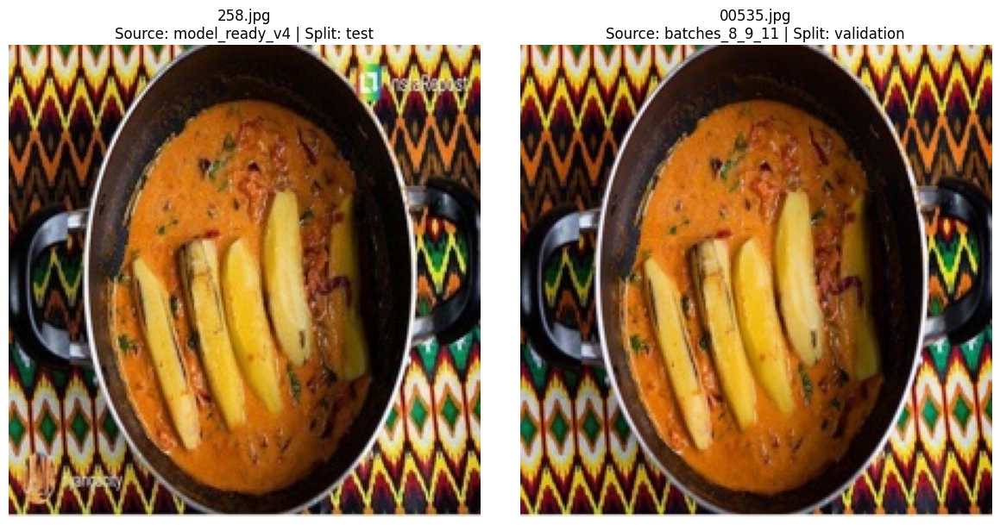

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    f"{audit_dir}/combined_annotations_staging_v1.csv"
)

images = [
    df[df["filename"] == "258.jpg"].iloc[0],
    df[df["filename"] == "00535.jpg"].iloc[0]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, record in zip(axes, images):
    img = Image.open(record["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f'{record["filename"]}\n'
        f'Source: {record["source"]} | Split: {record["split"]}'
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import os

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

input_file = os.path.join(
    audit_dir, "combined_annotations_staging_v1.csv"
)

df = pd.read_csv(input_file)

# Identify the duplicate
duplicate = df[
    (df["filename"] == "00535.jpg") &
    (df["source"] == "batches_8_9_11")
]

print("Duplicate records found:", len(duplicate))

# Keep 258.jpg in test; exclude 00535.jpg
df = df.drop(duplicate.index).copy()

print("\nUPDATED TOTAL:", len(df))
print("\nSOURCE DISTRIBUTION:")
print(df["source"].value_counts())

print("\nSPLIT DISTRIBUTION:")
print(df["split"].value_counts(dropna=False))

# Save a new version
output_file = os.path.join(
    audit_dir, "combined_annotations_clean_v1.csv"
)

df.to_csv(output_file, index=False)

print("\nSaved:", output_file)

Duplicate records found: 1

UPDATED TOTAL: 639

SOURCE DISTRIBUTION:
source
model_ready_v4    433
batches_8_9_11    125
Extras2            81
Name: count, dtype: int64

SPLIT DISTRIBUTION:
split
train         386
test           97
NaN            81
validation     75
Name: count, dtype: int64

Saved: /content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_clean_v1.csv


In [ ]:
import pandas as pd
import numpy as np
import os

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    os.path.join(audit_dir, "combined_annotations_clean_v1.csv")
)

label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Separate Extras2 and existing records
extras = df[df["source"] == "Extras2"].copy()
existing = df[df["source"] != "Extras2"].copy()

# Reset index so positional indices are safe
extras = extras.reset_index(drop=True)

assert len(extras) == 81

# Prepare multi-label data
X = np.arange(len(extras)).reshape(-1, 1)
y = extras[label_columns].astype(int).values

# First split: 14 images for testing
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=14/81,
    random_state=42
)

remaining_idx, test_idx = next(split1.split(X, y))

# Second split: 11 images for validation
X_remaining = X[remaining_idx]
y_remaining = y[remaining_idx]

split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=11/67,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(X_remaining, y_remaining)
)

# Assign splits
extras["split"] = "train"
extras.loc[val_idx + 0, "split"] = "validation"
extras.loc[test_idx, "split"] = "test"

# Recombine
final_df = pd.concat(
    [existing, extras],
    ignore_index=True
)

print("EXTRAS2 SPLIT COUNTS:")
print(extras["split"].value_counts())

print("\nCOMBINED SPLIT COUNTS:")
print(final_df["split"].value_counts())

print("\nPOSITIVE LABELS BY SPLIT:")
print(
    final_df.groupby("split")[label_columns].sum().T
)

print("\nTOTAL RECORDS:", len(final_df))

# Save
output_file = os.path.join(
    audit_dir, "combined_annotations_split_v1.csv"
)

final_df.to_csv(output_file, index=False)

print("\nSaved:", output_file)

EXTRAS2 SPLIT COUNTS:
split
train         56
test          15
validation    10
Name: count, dtype: int64

COMBINED SPLIT COUNTS:
split
train         442
test          112
validation     85
Name: count, dtype: int64

POSITIVE LABELS BY SPLIT:
split        test  train  validation
bhaji           8     36           8
chapati         6     44          12
githeri        12     47           8
kachumbari     16     47          10
kukuchoma      13     43          10
mandazi         8     34           5
masalachips     7     23           6
matoke         15     34           9
mukimo         11     24           9
nyamachoma     10     44           7
pilau           8     34           4
sukumawiki     19     52          10
ugali          12     55           7
samosa          2     20           0
rice            9     32           7
beef            5     30           6
beef_stew       3     26           6
beans           3     20           4
avocado         8     35           7
spaghetti       0 

In [ ]:
import pandas as pd

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    f"{audit_dir}/combined_annotations_split_v1.csv"
)

rare_labels = ["samosa", "spaghetti", "tilapia"]

for label in rare_labels:
    print("\n" + "=" * 45)
    print("CATEGORY:", label)

    print("\nDistribution:")
    print(pd.crosstab(df["split"], df[label]))

    print("\nPositive training examples:")
    display(
        df[
            (df[label] == 1) &
            (df["split"] == "train")
        ][["filename", "source", "split", "image_path"]]
    )



CATEGORY: samosa

Distribution:
samosa        0   1
split              
test        110   2
train       422  20
validation   85   0

Positive training examples:


,filename,source,split,image_path
7,1654404224462698318.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
104,1993581233037379596.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
106,2002426884639181630.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
165,samosa_0001.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
166,samosa_0002.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
167,samosa_0003.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
168,samosa_0004.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
169,samosa_0005.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
170,samosa_0006.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
171,samosa_0007.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...



CATEGORY: spaghetti

Distribution:
spaghetti     0   1
split              
test        112   0
train       430  12
validation   84   1

Positive training examples:


,filename,source,split,image_path
27,1039222797023324062.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
173,spaghetti_0001.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
174,spaghetti_0002.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
175,spaghetti_0003.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
176,spaghetti_0004.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
177,spaghetti_0005.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
178,spaghetti_0006.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
179,spaghetti_0007.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
279,116.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
280,118.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...



CATEGORY: tilapia

Distribution:
tilapia       0   1
split              
test        112   0
train       428  14
validation   85   0

Positive training examples:


,filename,source,split,image_path
75,1347900190610422316.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
110,1940560423258660172.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
117,1950948864374706879.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
139,1624548491747444669.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/split_dataset...
180,tilapia_0001.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
181,tilapia_0002.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
182,tilapia_0003.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
183,tilapia_0004.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
184,tilapia_0005.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...
185,tilapia_0006.jpg,model_ready_v4,train,/content/drive/MyDrive/Food_data/Extras_standa...


In [ ]:
import pandas as pd

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    f"{audit_dir}/combined_annotations_split_v1.csv"
)

rare_labels = ["samosa", "spaghetti", "tilapia"]

for label in rare_labels:
    print("\n" + "=" * 55)
    print("CATEGORY:", label)

    candidates = df[
        (df[label] == 1) &
        (df["split"] == "train")
    ].copy()

    other_labels = [
        c for c in rare_labels if c != label
    ]

    print("Training examples:", len(candidates))

    display(
        candidates[
            ["filename", "source", "image_path"] +
            rare_labels
        ]
    )



CATEGORY: samosa
Training examples: 20


,filename,source,image_path,samosa,spaghetti,tilapia
7,1654404224462698318.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,1,0,0
104,1993581233037379596.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,1,0,0
106,2002426884639181630.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,1,0,0
165,samosa_0001.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
166,samosa_0002.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
167,samosa_0003.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
168,samosa_0004.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
169,samosa_0005.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
170,samosa_0006.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0
171,samosa_0007.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,1,0,0



CATEGORY: spaghetti
Training examples: 12


,filename,source,image_path,samosa,spaghetti,tilapia
27,1039222797023324062.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,1,0
173,spaghetti_0001.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
174,spaghetti_0002.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
175,spaghetti_0003.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
176,spaghetti_0004.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
177,spaghetti_0005.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
178,spaghetti_0006.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
179,spaghetti_0007.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,1,0
279,116.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,1,0
280,118.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,1,0



CATEGORY: tilapia
Training examples: 14


,filename,source,image_path,samosa,spaghetti,tilapia
75,1347900190610422316.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,0,1
110,1940560423258660172.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,0,1
117,1950948864374706879.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,0,1
139,1624548491747444669.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/split_dataset...,0,0,1
180,tilapia_0001.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1
181,tilapia_0002.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1
182,tilapia_0003.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1
183,tilapia_0004.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1
184,tilapia_0005.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1
185,tilapia_0006.jpg,model_ready_v4,/content/drive/MyDrive/Food_data/Extras_standa...,0,0,1


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    f"{audit_dir}/combined_annotations_split_v1.csv"
)

rare_targets = {
    "samosa": {"train": 16, "validation": 3, "test": 3},
    "spaghetti": {"train": 9, "validation": 2, "test": 2},
    "tilapia": {"train": 10, "validation": 2, "test": 2}
}

proposed = df.copy()
changes = []

for label, targets in rare_targets.items():

    # Find positive examples currently in training
    train_candidates = proposed[
        (proposed[label] == 1) &
        (proposed["split"] == "train")
    ]

    # Calculate how many need moving
    val_needed = targets["validation"] - (
        (proposed[label] == 1) &
        (proposed["split"] == "validation")
    ).sum()

    test_needed = targets["test"] - (
        (proposed[label] == 1) &
        (proposed["split"] == "test")
    ).sum()

    if val_needed < 0 or test_needed < 0:
        raise ValueError(f"Existing {label} distribution exceeds target.")

    if val_needed + test_needed > len(train_candidates):
        raise ValueError(f"Not enough training examples for {label}.")

    # Select candidates reproducibly
    selected = train_candidates.sample(
        n=val_needed + test_needed,
        random_state=42
    )

    val_rows = selected.index[:val_needed]
    test_rows = selected.index[val_needed:]

    proposed.loc[val_rows, "split"] = "validation"
    proposed.loc[test_rows, "split"] = "test"

    for idx in val_rows:
        changes.append([idx, label, "train", "validation"])

    for idx in test_rows:
        changes.append([idx, label, "train", "test"])

# Inspect proposed distribution
print("PROPOSED RARE LABEL DISTRIBUTIONS")

for label in rare_targets:
    print(f"\n{label.upper()}")
    print(pd.crosstab(proposed["split"], proposed[label]))

# Check all categories
label_columns = list(rare_targets.keys()) + [
    c for c in [
        "bhaji", "chapati", "githeri", "kachumbari",
        "kukuchoma", "mandazi", "masalachips", "matoke",
        "mukimo", "nyamachoma", "pilau", "sukumawiki",
        "ugali", "rice", "beef", "beef_stew",
        "beans", "avocado", "chips"
    ] if c in proposed.columns
]

print("\nALL CATEGORY DISTRIBUTIONS:")
print(proposed.groupby("split")[label_columns].sum().T)

# Save proposal separately
proposal_file = f"{audit_dir}/split_reassignment_proposal.csv"
proposed.to_csv(proposal_file, index=False)

print("\nChanges proposed:", len(changes))
print("Proposal saved:", proposal_file)

PROPOSED RARE LABEL DISTRIBUTIONS

SAMOSA
samosa        0   1
split              
test        114   3
train       415  16
validation   88   3

SPAGHETTI
spaghetti     0  1
split             
test        115  2
train       422  9
validation   89  2

TILAPIA
tilapia       0   1
split              
test        115   2
train       421  10
validation   89   2

ALL CATEGORY DISTRIBUTIONS:
split        test  train  validation
samosa          3     16           3
spaghetti       2      9           2
tilapia         2     10           2
bhaji           8     35           9
chapati         6     44          12
githeri        13     46           8
kachumbari     18     44          11
kukuchoma      13     43          10
mandazi         8     34           5
masalachips     7     23           6
matoke         16     33           9
mukimo         11     24           9
nyamachoma     11     42           8
pilau           9     32           5
sukumawiki     19     52          10
ugali          12     

In [ ]:
import pandas as pd
import os

audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

proposal_file = f"{audit_dir}/split_reassignment_proposal.csv"
final_file = f"{audit_dir}/combined_annotations_final_v1.csv"

df = pd.read_csv(proposal_file)

label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

# Save final version
df.to_csv(final_file, index=False)

# Validation checks
print("TOTAL IMAGES:", len(df))
print("\nSPLIT COUNTS:")
print(df["split"].value_counts())

print("\nDUPLICATE IMAGE PATHS:", df["image_path"].duplicated().sum())

missing_files = (~df["image_path"].apply(os.path.isfile)).sum()
print("MISSING IMAGE FILES:", missing_files)

invalid_values = {
    label: sorted(df[label].dropna().unique().tolist())
    for label in label_columns
    if not df[label].isin([0, 1]).all()
}

print("INVALID LABEL VALUES:", invalid_values)
print("MISSING LABEL VALUES:", df[label_columns].isna().sum().sum())

print("\nPOSITIVE LABEL COUNTS:")
print(df[label_columns].sum().sort_values())

print("\nFINAL FILE:", final_file)

TOTAL IMAGES: 639

SPLIT COUNTS:
split
train         431
test          117
validation     91
Name: count, dtype: int64

DUPLICATE IMAGE PATHS: 0
MISSING IMAGE FILES: 0
INVALID LABEL VALUES: {}
MISSING LABEL VALUES: 0

POSITIVE LABEL COUNTS:
spaghetti      13
tilapia        14
chips          18
samosa         22
beans          27
beef_stew      35
masalachips    36
beef           41
mukimo         44
pilau          46
mandazi        47
rice           48
avocado        50
bhaji          52
matoke         58
nyamachoma     61
chapati        62
kukuchoma      66
githeri        67
kachumbari     73
ugali          74
sukumawiki     81
dtype: int64

FINAL FILE: /content/drive/MyDrive/Food_data/dataset_audit/combined_annotations_final_v1.csv


In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np

# Load final annotations
audit_dir = "/content/drive/MyDrive/Food_data/dataset_audit"

df = pd.read_csv(
    f"{audit_dir}/combined_annotations_final_v1.csv"
)

# Canonical label order
label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "chips", "tilapia"
]

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, labels):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, labels

def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values

    labels = dataframe[label_columns].values.astype("float32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

# Separate splits
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "validation"]
test_df = df[df["split"] == "test"]

# Create TensorFlow datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

# Inspect one batch
images, labels = next(iter(train_ds))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of output labels:", labels.shape[1])

Training batches: 14
Validation batches: 3
Testing batches: 4

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 22)
Number of output labels: 22


In [42]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

NUM_CLASSES = 22

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1)
])

# Pre-trained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="sigmoid"
)(x)

multilabel_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Kenyan_Food_MultiLabel_CNN"
)

# Compile
multilabel_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=NUM_CLASSES
        ),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

multilabel_model.summary()

Model: "Kenyan_Food_MultiLabel_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,591,574 (9.89 MB)

 Trainable params: 333,590 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [43]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Calculate positive and negative examples using training data only
positive_counts = train_df[label_columns].sum().values
negative_counts = len(train_df) - positive_counts

# Calculate capped positive weights
positive_weights = np.sqrt(
    negative_counts / np.maximum(positive_counts, 1)
)

positive_weights = np.clip(positive_weights, 1.0, 5.0)

weights_tensor = tf.constant(
    positive_weights,
    dtype=tf.float32
)

print("POSITIVE CLASS WEIGHTS:")
for label, weight in zip(label_columns, positive_weights):
    print(f"{label}: {weight:.2f}")

# Weighted binary cross-entropy
def weighted_binary_crossentropy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.clip_by_value(
        y_pred, 1e-7, 1.0 - 1e-7
    )

    loss = -(
        weights_tensor * y_true * tf.math.log(y_pred)
        + (1 - y_true) * tf.math.log(1 - y_pred)
    )

    return tf.reduce_mean(loss, axis=-1)

# Compile model
multilabel_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=weighted_binary_crossentropy,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=22
        )
    ]
)

# Save the best version separately
model_path = (
    "/content/drive/MyDrive/Food_data/"
    "multilabel_mobilenetv2_best_v1.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

print("\nModel ready for weighted training.")

POSITIVE CLASS WEIGHTS:
bhaji: 3.36
chapati: 2.97
githeri: 2.89
kachumbari: 2.97
kukuchoma: 3.00
mandazi: 3.42
masalachips: 4.21
matoke: 3.47
mukimo: 4.12
nyamachoma: 3.04
pilau: 3.53
sukumawiki: 2.70
ugali: 2.64
samosa: 5.00
rice: 3.53
beef: 3.66
beef_stew: 3.95
beans: 4.53
avocado: 3.36
spaghetti: 5.00
chips: 5.00
tilapia: 5.00

Model ready for weighted training.


In [44]:
print(tf.config.list_physical_devices('GPU'))


[]


In [45]:
history = multilabel_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - auc: 0.5383 - binary_accuracy: 0.8208 - loss: 0.7108 - val_auc: 0.6971 - val_binary_accuracy: 0.9071 - val_loss: 0.5771 - learning_rate: 0.0010
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - auc: 0.7083 - binary_accuracy: 0.8847 - loss: 0.5564 - val_auc: 0.7784 - val_binary_accuracy: 0.9116 - val_loss: 0.5270 - learning_rate: 0.0010
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - auc: 0.7931 - binary_accuracy: 0.9072 - loss: 0.4828 - val_auc: 0.8202 - val_binary_accuracy: 0.9251 - val_loss: 0.4811 - learning_rate: 0.0010
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - auc: 0.8526 - binary_accuracy: 0.9128 - loss: 0.4282 - val_auc: 0.8482 - val_binary_accuracy: 0.9231 - val_loss: 0.4572 - learning_rate: 0.0010
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - auc: 0.8728 - binary_accuracy: 0.9205 - loss: 0.3934 - val_auc: 0.8550 - val_binary_accuracy: 0.9261 - val_loss: 0.4326 - learning_rate: 0.0010
Epoch 6/15
14/14 ━━━

In [46]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate validation predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

y_pred = multilabel_model.predict(val_ds)

# Initial threshold
threshold = 0.5
y_pred_binary = (y_pred >= threshold).astype(int)

# Calculate per-category metrics
results = []

for i, label in enumerate(label_columns):

    results.append({
        "Food": label,
        "Precision": precision_score(
            y_true[:, i], y_pred_binary[:, i],
            zero_division=0
        ),
        "Recall": recall_score(
            y_true[:, i], y_pred_binary[:, i],
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true[:, i], y_pred_binary[:, i],
            zero_division=0
        ),
        "AUC": roc_auc_score(
            y_true[:, i], y_pred[:, i]
        ),
        "Actual positives": int(y_true[:, i].sum())
    })

results_df = pd.DataFrame(results)

print("VALIDATION RESULTS BY FOOD CATEGORY")
display(
    results_df.round(3).sort_values(
        "F1-score", ascending=False
    )
)

print("\nOVERALL VALIDATION PERFORMANCE")
print("Micro F1:", round(
    f1_score(y_true, y_pred_binary, average="micro",
             zero_division=0), 3
))
print("Macro F1:", round(
    f1_score(y_true, y_pred_binary, average="macro",
             zero_division=0), 3
))
print("Weighted F1:", round(
    f1_score(y_true, y_pred_binary, average="weighted",
             zero_division=0), 3
))

3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 4s/step
VALIDATION RESULTS BY FOOD CATEGORY


,Food,Precision,Recall,F1-score,AUC,Actual positives
21,tilapia,0.667,1.000,0.800,1.000,2
10,pilau,0.667,0.800,0.727,0.942,5
1,chapati,0.667,0.667,0.667,0.926,12
13,samosa,0.667,0.667,0.667,0.811,3
6,masalachips,0.571,0.667,0.615,0.980,6
9,nyamachoma,0.800,0.500,0.615,0.884,8
7,matoke,0.545,0.667,0.600,0.904,9
2,githeri,0.556,0.625,0.588,0.955,8
17,beans,0.667,0.500,0.571,0.767,4
0,bhaji,0.500,0.667,0.571,0.875,9



OVERALL VALIDATION PERFORMANCE
Micro F1: 0.494
Macro F1: 0.472
Weighted F1: 0.482


In [47]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

threshold_results = []

thresholds = np.arange(0.05, 0.96, 0.05)

best_thresholds = {}

for i, label in enumerate(label_columns):

    true = y_true[:, i]
    probabilities = y_pred[:, i]

    best_f1 = -1
    best_threshold = 0.5

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        score = f1_score(
            true,
            predictions,
            zero_division=0
        )

        # Prefer threshold closest to 0.5 in case of ties
        if (
            score > best_f1 or
            (score == best_f1 and
             abs(threshold - 0.5) <
             abs(best_threshold - 0.5))
        ):
            best_f1 = score
            best_threshold = threshold

    best_thresholds[label] = best_threshold

    threshold_results.append({
        "Food": label,
        "Default F1": f1_score(
            true,
            (probabilities >= 0.5).astype(int),
            zero_division=0
        ),
        "Best threshold": best_threshold,
        "Best validation F1": best_f1,
        "Actual positives": int(true.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print("THRESHOLD TUNING RESULTS")
display(
    threshold_df.sort_values(
        "Best validation F1",
        ascending=False
    ).round(3)
)

print("\nTUNED MICRO F1:")
tuned_predictions = np.column_stack([
    (y_pred[:, i] >= best_thresholds[label]).astype(int)
    for i, label in enumerate(label_columns)
])

print(round(
    f1_score(y_true, tuned_predictions,
             average="micro", zero_division=0), 3
))

print("\nTUNED MACRO F1:")
print(round(
    f1_score(y_true, tuned_predictions,
             average="macro", zero_division=0), 3
))


THRESHOLD TUNING RESULTS


,Food,Default F1,Best threshold,Best validation F1,Actual positives
10,pilau,0.727,0.55,0.800,5
6,masalachips,0.615,0.55,0.800,6
21,tilapia,0.800,0.50,0.800,2
19,spaghetti,0.000,0.40,0.800,2
1,chapati,0.667,0.60,0.762,12
5,mandazi,0.545,0.65,0.750,5
13,samosa,0.667,0.50,0.667,3
17,beans,0.571,0.70,0.667,4
12,ugali,0.429,0.75,0.667,8
2,githeri,0.588,0.45,0.667,8



TUNED MICRO F1:
0.621

TUNED MACRO F1:
0.621


In [48]:
# Inspect validation predictions for chips

chips_index = label_columns.index("chips")

chips_check = val_df.copy().reset_index(drop=True)

chips_check["Actual"] = y_true[:, chips_index]
chips_check["Predicted probability"] = y_pred[:, chips_index]

chips_check["Prediction"] = (
    chips_check["Predicted probability"] >= 0.5
).astype(int)

chips_check["Masalachips actual"] = (
    chips_check["masalachips"].values
)

print("CHIPS VALIDATION EXAMPLES")

display(
    chips_check[
        [
            "filename",
            "Actual",
            "Predicted probability",
            "Prediction",
            "Masalachips actual"
        ]
    ].sort_values("Predicted probability", ascending=False)
)

print("\nAVERAGE PREDICTION PROBABILITY")
print(
    chips_check.groupby("Actual")[
        "Predicted probability"
    ].mean()
)

CHIPS VALIDATION EXAMPLES


,filename,Actual,Predicted probability,Prediction,Masalachips actual
13,930752990364050942.jpg,0.0,0.537976,1,1
43,191.jpg,0.0,0.286997,0,0
55,307.jpg,0.0,0.273266,0,0
3,1977102378291084793.jpg,0.0,0.240946,0,0
44,193.jpg,0.0,0.232493,0,0
...,...,...,...,...,...
18,1971804591360359479_2.jpg,0.0,0.003735,0,0
49,269.jpg,0.0,0.002916,0,0
22,1992913062625834463.jpg,0.0,0.002314,0,0
6,1973720873103114148.jpg,0.0,0.001771,0,0



AVERAGE PREDICTION PROBABILITY
Actual
0.0    0.052623
1.0    0.013540
Name: Predicted probability, dtype: float32


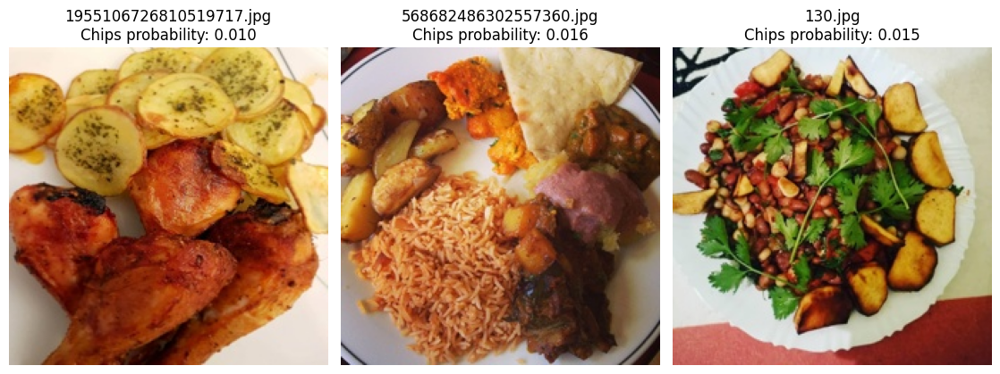

In [49]:
import matplotlib.pyplot as plt
import os

chips_rows = chips_check[chips_check["Actual"] == 1]

plt.figure(figsize=(15, 10))

for position, (_, row) in enumerate(chips_rows.iterrows()):

    image = tf.keras.utils.load_img(
        row["image_path"],
        target_size=(224, 224)
    )

    plt.subplot(2, 4, position + 1)
    plt.imshow(image)
    plt.title(
        f'{row["filename"]}\n'
        f'Chips probability: {row["Predicted probability"]:.3f}'
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [50]:
label_columns = [
    "bhaji", "chapati", "githeri", "kachumbari",
    "kukuchoma", "mandazi", "masalachips", "matoke",
    "mukimo", "nyamachoma", "pilau", "sukumawiki",
    "ugali", "samosa", "rice", "beef", "beef_stew",
    "beans", "avocado", "spaghetti", "tilapia"
]

NUM_CLASSES = len(label_columns)

print("Number of food categories:", NUM_CLASSES)
print(label_columns)

Number of food categories: 21
['bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali', 'samosa', 'rice', 'beef', 'beef_stew', 'beans', 'avocado', 'spaghetti', 'tilapia']
